In [58]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams.update({'errorbar.capsize': 3})
plt.rcParams['xtick.labelsize']= 13
plt.rcParams['ytick.labelsize']= 13
plt.rcParams.update({'axes.labelsize': 16})

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [59]:
from astropy.io import ascii
from scipy.stats import mannwhitneyu

In [60]:
import pickle

In [61]:
from astropy.time import Time

In [62]:
#open the pickle file with line fit results
with open('line_fit_results_neid_expres_overlap_2024_fitrange_p15.pkl', 'rb') as f:
    data = pickle.load(f)

In [63]:
len(data)

60

In [64]:
(data[0])['NEID_fits'][0].keys()

dict_keys(['line_wl', 'order', 'line_string', 'cen_wl_order', 'order_number', 'amp', 'amp_err', 'cen', 'cen_err', 'wid', 'wid_err', 'bas', 'bas_err', 'slope_err', 'slope', 'slope0', 'slope0_err', 'bas0', 'bas0_err', 's2n', 'chi2', 'bic', 'r', 'line_center_index', 'line_depth', 'line_id'])

In [65]:
for item in data[0].keys():
    print(item, len(data[0][item]))

index 4
NEID_fits 2886
EXPRES_fits 2156
overlap_mid 23


In [66]:
data[0]['index']

'0000'

In [67]:
times_string=[item['overlap_mid'] for item in data]
times=[Time(t).mjd for t in times_string]
times

[np.float64(60318.8152634838),
 np.float64(60319.81513804398),
 np.float64(60321.81577804398),
 np.float64(60322.816261597225),
 np.float64(60323.81631045139),
 np.float64(60325.86468628472),
 np.float64(60327.834665092596),
 np.float64(60335.79144644676),
 np.float64(60336.81174034722),
 np.float64(60340.77245752315),
 np.float64(60344.873720208336),
 np.float64(60351.83891179398),
 np.float64(60352.81364684028),
 np.float64(60353.81343778935),
 np.float64(60354.81376751157),
 np.float64(60355.766303125),
 np.float64(60356.8134478125),
 np.float64(60357.82551542824),
 np.float64(60358.846501608794),
 np.float64(60360.88520842593),
 np.float64(60361.75038842593),
 np.float64(60370.835393113426),
 np.float64(60403.74103502315),
 np.float64(60404.79633601852),
 np.float64(60407.746990555555),
 np.float64(60409.81354300926),
 np.float64(60410.81345451389),
 np.float64(60411.813706168985),
 np.float64(60412.764890405095),
 np.float64(60414.82265847222),
 np.float64(60415.88356008102),
 np.

In [68]:
indicies=[ind['index'] for ind in data]
indicies


['0000',
 '0001',
 '0002',
 '0003',
 '0004',
 '0005',
 '0006',
 '0007',
 '0008',
 '0009',
 '0010',
 '0011',
 '0012',
 '0013',
 '0014',
 '0015',
 '0016',
 '0017',
 '0018',
 '0019',
 '0020',
 '0021',
 '0023',
 '0024',
 '0025',
 '0026',
 '0027',
 '0028',
 '0029',
 '0030',
 '0031',
 '0032',
 '0033',
 '0034',
 '0035',
 '0036',
 '0037',
 '0038',
 '0039',
 '0040',
 '0041',
 '0042',
 '0043',
 '0044',
 '0045',
 '0046',
 '0047',
 '0048',
 '0049',
 '0050',
 '0051',
 '0052',
 '0053',
 '0054',
 '0055',
 '0056',
 '0057',
 '0058',
 '0059',
 '0060']

In [69]:
overlapping_lines={index: [] for index in indicies}


In [70]:
dat_item2=data[0]
NEID_dat=dat_item2['NEID_fits']
EXPRES_dat=dat_item2['EXPRES_fits']
NEID_lines=[]
EXPRES_lines=[]
for line_fit in NEID_dat:
    line_id=line_fit['line_id']
    line_wl=line_fit['line_wl']
    line_order=line_fit['order_number']
    NEID_lines.append({'line_id': line_id, 'line_wl': line_wl, 'order_number': line_order, 'line_depth': line_fit['line_depth']})

matched_lines=[]
for line_fit in EXPRES_dat:
    line_id=line_fit['line_id']
    line_wl=line_fit['line_wl']
    line_order=line_fit['order_number']
    EXPRES_lines.append({'line_id': line_id, 'line_wl': line_wl, 'order_number': line_order})
    
    #check if line_id is in NEID_lines
    for line in NEID_lines:
        if line['line_id'] == line_id and line['order_number'] == line_order:
            line_string=str(line['line_wl'])+'_'+str(line['order_number'])
            matched_lines.append({'line_id': line_id, 'line_wl': line_wl, 'order_number': line_order,
                                   'line_string': line_string,'line_depth': line['line_depth']})
print(len(matched_lines))

2155


In [71]:
data[0]['EXPRES_fits']

[{'line_wl': np.float64(3882.134036576609),
  'order': 2,
  'line_string': '3882.134036576609_2',
  'cen_wl_order': np.float64(3877.176488553151),
  'order_number': np.int64(2),
  'amp': np.float64(-11.088419571063703),
  'amp_err': np.float64(1.9121971282013739),
  'cen': np.float64(-0.26061595644396696),
  'cen_err': np.float64(0.276355921120023),
  'wid': np.float64(5.99869591660224),
  'wid_err': np.float64(0.5375696902044587),
  'bas': np.float64(0.9939453837466655),
  'bas_err': np.float64(0.0687447249971703),
  'slope_err': np.float64(0.002515936172228428),
  'slope': np.float64(-0.00013994078300180556),
  'slope0': np.float64(-0.0014993878164828484),
  'slope0_err': np.float64(0.00021686847874325212),
  'bas0': np.float64(0.08380460528200122),
  'bas0_err': np.float64(0.0054742605324453394),
  's2n': array([83.53239611, 84.16534551, 84.45005418, 81.52177496, 79.40046905,
         76.87655401, 71.89393903, 68.77033902, 61.53586818, 57.01703303,
         54.40827463, 49.67883404,

In [72]:
EXPRES_lines

[{'line_id': np.int64(1),
  'line_wl': np.float64(3882.134036576609),
  'order_number': np.int64(2)},
 {'line_id': np.int64(3),
  'line_wl': np.float64(3882.7272483847664),
  'order_number': np.int64(2)},
 {'line_id': np.int64(9),
  'line_wl': np.float64(3884.7318502049066),
  'order_number': np.int64(2)},
 {'line_id': np.int64(9),
  'line_wl': np.float64(3884.7318502049066),
  'order_number': np.int64(3)},
 {'line_id': np.int64(14),
  'line_wl': np.float64(3886.6115251666934),
  'order_number': np.int64(2)},
 {'line_id': np.int64(14),
  'line_wl': np.float64(3886.6115251666934),
  'order_number': np.int64(3)},
 {'line_id': np.int64(15),
  'line_wl': np.float64(3886.84777055226),
  'order_number': np.int64(2)},
 {'line_id': np.int64(15),
  'line_wl': np.float64(3886.84777055226),
  'order_number': np.int64(3)},
 {'line_id': np.int64(16),
  'line_wl': np.float64(3887.8962318114072),
  'order_number': np.int64(2)},
 {'line_id': np.int64(16),
  'line_wl': np.float64(3887.8962318114072),
 

In [73]:
NEID_lines

[{'line_id': np.int64(1),
  'line_wl': np.float64(3882.134036576609),
  'order_number': np.int64(1),
  'line_depth': np.float64(0.5150686662735857)},
 {'line_id': np.int64(1),
  'line_wl': np.float64(3882.134036576609),
  'order_number': np.int64(2),
  'line_depth': np.float64(0.5150686662735857)},
 {'line_id': np.int64(1),
  'line_wl': np.float64(3882.134036576609),
  'order_number': np.int64(3),
  'line_depth': np.float64(0.5150686662735857)},
 {'line_id': np.int64(3),
  'line_wl': np.float64(3882.7272483847664),
  'order_number': np.int64(1),
  'line_depth': np.float64(0.4626482900339974)},
 {'line_id': np.int64(3),
  'line_wl': np.float64(3882.7272483847664),
  'order_number': np.int64(2),
  'line_depth': np.float64(0.4626482900339974)},
 {'line_id': np.int64(3),
  'line_wl': np.float64(3882.7272483847664),
  'order_number': np.int64(3),
  'line_depth': np.float64(0.4626482900339974)},
 {'line_id': np.int64(9),
  'line_wl': np.float64(3884.7318502049066),
  'order_number': np.int64

In [74]:

def get_matched_lines(dat_item):
    NEID_dat=dat_item['NEID_fits']
    EXPRES_dat=dat_item['EXPRES_fits']
    NEID_lines=[]
    for line_fit in NEID_dat:
        line_id=line_fit['line_id']
        line_wl=line_fit['line_wl']
        line_order=line_fit['order_number']
        NEID_lines.append({'line_id': line_id, 'line_wl': line_wl, 'order_number': line_order, 
                           'line_depth': line_fit['line_depth']})

    matched_lines=[]
    for line_fit in EXPRES_dat:
        line_id=line_fit['line_id']
        line_wl=line_fit['line_wl']
        line_order=line_fit['order_number']
        #check if line_id is in NEID_lines
        for line in NEID_lines:
            if line['line_id'] == line_id and line['order_number'] == line_order:
                line_string=str(line['line_wl'])+'_'+str(line['order_number'])
                matched_lines.append({'line_id': line_id, 'line_wl': line_wl, 'order_number': line_order,
                                       'line_string': line_string,'line_depth': line['line_depth']})
    #print(len(matched_lines))
    return matched_lines

In [75]:

all_good_lines=[]

In [76]:
len(data)

60

In [77]:
all_lines_all=[]
all_lines_strings=[]
for item in data:  # Adjust the slice as needed
    #print(1)
    matched_lines = get_matched_lines(item)
    #print(f"Number of matched lines for {item}: {len(matched_lines)}")
    lines_strings=[l['line_string'] for l in matched_lines]
    all_lines_all.extend(matched_lines)
    all_lines_strings.extend(lines_strings)

all_line_strings_unique = list(set(all_lines_strings))
print(len(all_lines_all),len(all_lines_strings), len(all_line_strings_unique))


129698 129698 2164


In [78]:
all_line_strings_unique.sort()
print(all_line_strings_unique[:100])

['3882.134036576609_2', '3882.134036576609_3', '3882.7272483847664_2', '3882.7272483847664_3', '3884.7318502049066_2', '3884.7318502049066_3', '3886.6115251666934_2', '3886.6115251666934_3', '3886.84777055226_2', '3886.84777055226_3', '3887.8962318114072_2', '3887.8962318114072_3', '3888.152342013541_2', '3888.152342013541_3', '3889.6170975366504_2', '3889.6170975366504_3', '3891.940572510654_2', '3891.940572510654_3', '3893.0273958264756_2', '3893.0273958264756_3', '3893.405436375459_2', '3893.405436375459_3', '3897.5725597378896_3', '3898.5529464208234_3', '3899.4873657988883_3', '3900.4830103985014_3', '3900.8139454679713_3', '3901.319662629716_3', '3902.0609527015436_3', '3902.6934833013465_3', '3905.177458248997_3', '3905.177458248997_4', '3906.111301599076_3', '3906.111301599076_4', '3906.6331998202795_3', '3906.6331998202795_4', '3908.5755568083014_3', '3908.5755568083014_4', '3909.0395486717343_3', '3909.0395486717343_4', '3909.371035570072_3', '3909.371035570072_4', '3911.9475

In [79]:
#for each item in all_lines, count the number of occurrences in all_lines_all
line_counts = {}
for line in all_line_strings_unique:
    line_counts[line] = sum(1 for l in all_lines_all if l['line_string'] == line) 

all_lines=[]
for string in all_line_strings_unique:
    for line in all_lines_all:
        if line['line_string'] == string:
            all_lines.append(line)
            break

In [80]:
len(all_lines), len(all_line_strings_unique)

(2164, 2164)

In [81]:
line_counts

{'3882.134036576609_2': 60,
 '3882.134036576609_3': 52,
 '3882.7272483847664_2': 60,
 '3882.7272483847664_3': 57,
 '3884.7318502049066_2': 60,
 '3884.7318502049066_3': 60,
 '3886.6115251666934_2': 60,
 '3886.6115251666934_3': 60,
 '3886.84777055226_2': 60,
 '3886.84777055226_3': 60,
 '3887.8962318114072_2': 60,
 '3887.8962318114072_3': 60,
 '3888.152342013541_2': 60,
 '3888.152342013541_3': 60,
 '3889.6170975366504_2': 60,
 '3889.6170975366504_3': 60,
 '3891.940572510654_2': 60,
 '3891.940572510654_3': 60,
 '3893.0273958264756_2': 60,
 '3893.0273958264756_3': 60,
 '3893.405436375459_2': 60,
 '3893.405436375459_3': 60,
 '3897.5725597378896_3': 60,
 '3898.5529464208234_3': 60,
 '3899.4873657988883_3': 60,
 '3900.4830103985014_3': 60,
 '3900.8139454679713_3': 60,
 '3901.319662629716_3': 60,
 '3902.0609527015436_3': 60,
 '3902.6934833013465_3': 60,
 '3905.177458248997_3': 60,
 '3905.177458248997_4': 47,
 '3906.111301599076_3': 60,
 '3906.111301599076_4': 57,
 '3906.6331998202795_3': 60,
 '

In [82]:
def good_line_check(line,r=.99):
    errs=['cen_err','amp_err','wid_err','bas_err']
    for err in errs:
        if line[err] == None:
            return False
    if line['amp'] >= 0:
        return False
    if line['amp'] < 0 and line['r'] > r and line['wid'] > 0 and (line['wid_err']/line['wid']) < 0.3 and (line['amp_err']/line['amp']) < 0.3:
        return True
    return False

In [83]:
#check to see if the lines have good data
min_good_lines = 30
good_lines=[]
for i,line in enumerate(all_lines):
    good_count = 0
    if line_counts[line['line_string']] >= min_good_lines:  #if the line appears frequently enough
        for dat_item in data:
            NEID_dat=dat_item['NEID_fits']
            EXPRES_dat=dat_item['EXPRES_fits']

            #find the corresponding line in each dataset
            NEID_line = None
            EXPRES_line = None
            for l in NEID_dat:
                if l['line_id'] == line['line_id'] and l['order_number'] == line['order_number']:
                    NEID_line = l
                    break
            for l in EXPRES_dat:
                if l['line_id'] == line['line_id'] and l['order_number'] == line['order_number']:
                    EXPRES_line = l
                    break

            #check if both lines have good data
            if NEID_line and EXPRES_line:
                #example condition, replace with actual criteria
                if good_line_check(NEID_line) and good_line_check(EXPRES_line): 
                    good_count += 1
    if good_count >= min_good_lines:
        good_lines.append(line)

In [84]:
good_lines
with open('good_lines.pkl','wb') as f:
    pickle.dump(good_lines,f)

In [85]:
len(good_lines)
good_line_wls = np.array([line['line_wl'] for line in good_lines])
good_line_depths = np.array([line['line_depth'] for line in good_lines])

In [86]:
#get line properties

line_measurements_NEID = {}
line_measurements_NEID['amps']=np.empty((len(good_lines), len(times)))
line_measurements_NEID['amps'][:]=np.nan

line_measurements_NEID['amp_errs']=np.empty((len(good_lines), len(times)))
line_measurements_NEID['amp_errs'][:]=np.nan
line_measurements_NEID['cens']=np.empty((len(good_lines), len(times)))
line_measurements_NEID['cens'][:]=np.nan
line_measurements_NEID['cen_errs']=np.empty((len(good_lines), len(times)))
line_measurements_NEID['cen_errs'][:]=np.nan
line_measurements_NEID['wids']=np.empty((len(good_lines), len(times)))
line_measurements_NEID['wids'][:]=np.nan
line_measurements_NEID['wid_errs']=np.empty((len(good_lines), len(times)))
line_measurements_NEID['wid_errs'][:]=np.nan

line_measurements_EXPRES = {}
line_measurements_EXPRES['amps']=np.empty((len(good_lines), len(times)))
line_measurements_EXPRES['amps'][:]=np.nan

line_measurements_EXPRES['amp_errs']=np.empty((len(good_lines), len(times)))
line_measurements_EXPRES['amp_errs'][:]=np.nan
line_measurements_EXPRES['cens']=np.empty((len(good_lines), len(times)))
line_measurements_EXPRES['cens'][:]=np.nan
line_measurements_EXPRES['cen_errs']=np.empty((len(good_lines), len(times)))
line_measurements_EXPRES['cen_errs'][:]=np.nan
line_measurements_EXPRES['wids']=np.empty((len(good_lines), len(times)))
line_measurements_EXPRES['wids'][:]=np.nan
line_measurements_EXPRES['wid_errs']=np.empty((len(good_lines), len(times)))
line_measurements_EXPRES['wid_errs'][:]=np.nan



for i,line in enumerate(good_lines):

    for t,dat_item in enumerate(data):
        NEID_dat=dat_item['NEID_fits']
        EXPRES_dat=dat_item['EXPRES_fits']

        #find the corresponding line in each dataset
        NEID_line = None
        EXPRES_line = None
        for l in NEID_dat:
            if l['line_id'] == line['line_id'] and l['order_number'] == line['order_number']:
                NEID_line = l
                break
        for l in EXPRES_dat:
            if l['line_id'] == line['line_id'] and l['order_number'] == line['order_number']:
                EXPRES_line = l
                break

        #check if both lines have good data
        if NEID_line and EXPRES_line:
            #example condition, replace with actual criteria
            if good_line_check(NEID_line) and good_line_check(EXPRES_line): 
                #print(NEID_line['amp'])
                line_measurements_NEID['amps'][i, t] = NEID_line['amp']
                line_measurements_NEID['amp_errs'][i, t] = NEID_line['amp_err']
                line_measurements_NEID['cens'][i, t] = NEID_line['cen']
                line_measurements_NEID['cen_errs'][i, t] = NEID_line['cen_err']
                line_measurements_NEID['wids'][i, t] = NEID_line['wid']
                line_measurements_NEID['wid_errs'][i, t] = NEID_line['wid_err']

                line_measurements_EXPRES['amps'][i, t] = EXPRES_line['amp']
                line_measurements_EXPRES['amp_errs'][i, t] = EXPRES_line['amp_err']
                line_measurements_EXPRES['cens'][i, t] = EXPRES_line['cen']
                line_measurements_EXPRES['cen_errs'][i, t] = EXPRES_line['cen_err']
                line_measurements_EXPRES['wids'][i, t] = EXPRES_line['wid']
                line_measurements_EXPRES['wid_errs'][i, t] = EXPRES_line['wid_err']


In [87]:
#for each line time series, find outliers and set both the measurement and error to NaN
outlier_cut=5 #number of standard deviations from the mean to consider an outlier

for key in line_measurements_NEID:
    if not key.endswith('_errs'):
        print(key)
        err_key=key[:-1]+'_errs'
        for line in range(len(line_measurements_NEID[key])):
            #calculate the mean and standard deviation of the line measurements
            mean = np.nanmean(line_measurements_NEID[key][line, :])
            std = np.nanstd(line_measurements_NEID[key][line, :])

            #find outliers
            outliers = np.abs(line_measurements_NEID[key][line, :] - mean) > outlier_cut * std
            if np.any(outliers):
                line_measurements_NEID[key][line, outliers] = np.nan
                line_measurements_NEID[err_key][line, outliers] = np.nan
for key in line_measurements_EXPRES:
    if not key.endswith('_errs'):
        err_key=key[:-1]+'_errs'
        for line in range(len(line_measurements_EXPRES[key])):
            #calculate the mean and standard deviation of the line measurements
            mean = np.nanmean(line_measurements_EXPRES[key][line, :])
            std = np.nanstd(line_measurements_EXPRES[key][line, :])

            #find outliers
            outliers = np.abs(line_measurements_EXPRES[key][line, :] - mean) > outlier_cut * std
            if np.any(outliers):
                line_measurements_EXPRES[key][line, outliers] = np.nan
                line_measurements_EXPRES[err_key][line, outliers] = np.nan

amps
cens
wids


In [88]:
#save fit results to pickele file

with open('NEID_line_fits.pkl','wb') as f:
    pickle.dump(line_measurements_NEID,f)
with open('EXPRES_line_fits.pkl','wb') as f:
    pickle.dump(line_measurements_EXPRES,f)

In [89]:
line_measurements_NEID

{'amps': array([[ -6.40594105,  -6.40010736,  -6.40625355, ...,  -6.412488  ,
          -6.42498338,  -6.42685237],
        [-12.99273009, -12.95362137,          nan, ..., -12.73580106,
         -12.8959169 , -13.10197827],
        [ -5.15942964,  -5.14832538,  -5.15363894, ...,  -5.15299354,
          -5.12845748,  -5.14286297],
        ...,
        [ -1.24116646,  -1.22817917,  -1.2179226 , ...,  -1.18402558,
          -1.15662792,  -1.19209154],
        [ -2.73008025,  -2.74420439,  -2.76219338, ...,  -2.78653154,
          -2.78365882,  -2.75494322],
        [ -2.03414787,  -2.04266392,          nan, ...,  -2.03625893,
          -2.01338932,  -2.01903039]], shape=(1292, 60)),
 'amp_errs': array([[0.10992287, 0.11222394, 0.11003703, ..., 0.10913091, 0.11508121,
         0.11356343],
        [0.36941363, 0.36218878,        nan, ..., 0.35458349, 0.33900922,
         0.3516212 ],
        [0.05212577, 0.04918599, 0.05410544, ..., 0.04810661, 0.05408552,
         0.05194822],
        ...

amp_errs


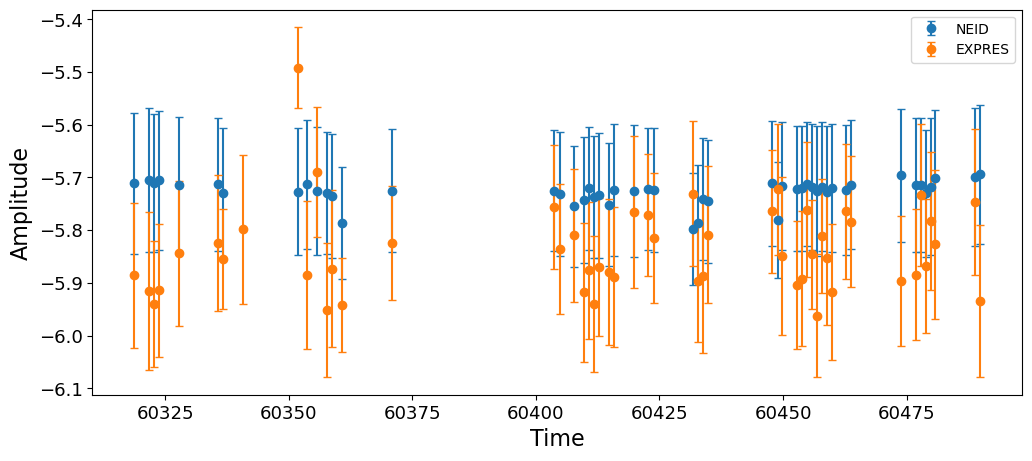

In [90]:
key='amps'
err_key=key[:-1]+'_errs'
print(err_key)

line=3


plt.errorbar(times,line_measurements_NEID[key][line,:], yerr=line_measurements_NEID[err_key][line,:], fmt='o',label='NEID')
plt.errorbar(times,line_measurements_EXPRES[key][line,:], yerr=line_measurements_EXPRES[err_key][line,:], fmt='o',label='EXPRES')
plt.legend()
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.show()


In [91]:
 np.nanmean(line_measurements_NEID['amps'], axis=1).shape

(1292,)

In [92]:
NEID_minus_means = [
    line_measurements_NEID[key] - np.nanmean(line_measurements_NEID[key], axis=1, keepdims=True)
    for key in line_measurements_NEID if not key.endswith('_errs')
]
EXPRES_minus_means = [
    line_measurements_EXPRES[key] - np.nanmean(line_measurements_EXPRES[key], axis=1, keepdims=True)
    for key in line_measurements_EXPRES if not key.endswith('_errs')
]

In [93]:
medians_NEID={key: np.nanmedian(line_measurements_NEID[key], axis=1, keepdims=True) for key in line_measurements_NEID if not key.endswith('_errs')}
medians_EXPRES={key: np.nanmedian(line_measurements_EXPRES[key], axis=1, keepdims=True) for key in line_measurements_EXPRES if not key.endswith('_errs')}


In [94]:
stds_NEID={key: np.nanstd(line_measurements_NEID[key], axis=1, keepdims=True) for key in line_measurements_NEID if not key.endswith('_errs')}
stds_EXPRES={key: np.nanstd(line_measurements_EXPRES[key], axis=1, keepdims=True) for key in line_measurements_EXPRES if not key.endswith('_errs')} 

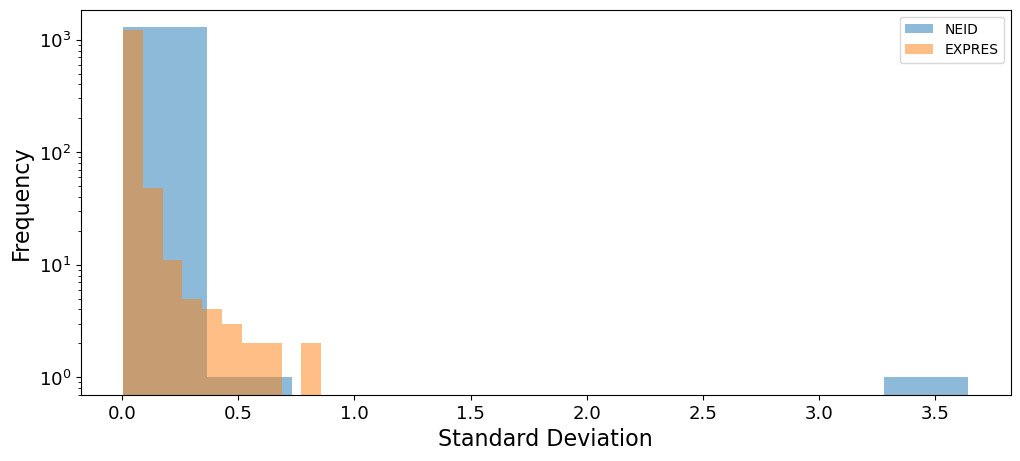

In [95]:

key='amps'
plt.hist(stds_NEID[key].flatten(),alpha=0.5,label='NEID')
plt.hist(stds_EXPRES[key].flatten(),alpha=0.5,label='EXPRES')
plt.yscale('log')
plt.xlabel('Standard Deviation')
plt.ylabel('Frequency')
plt.legend()
plt.show()

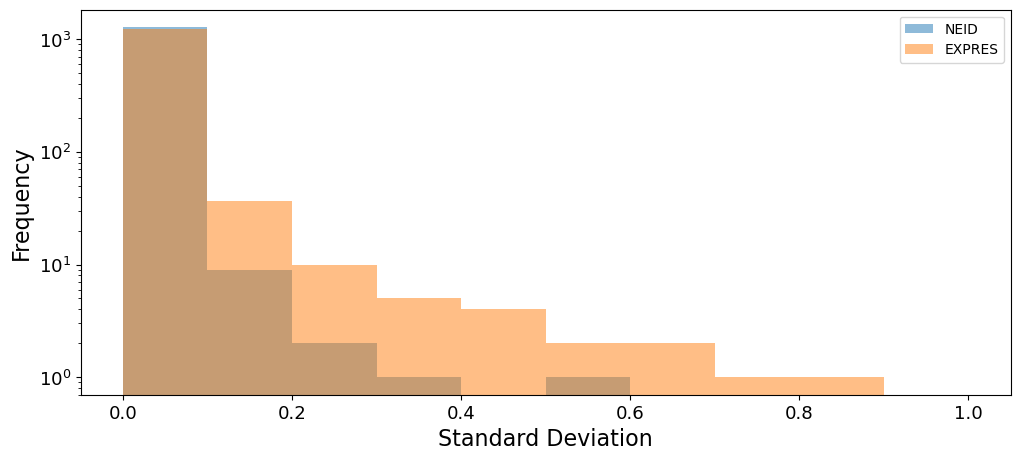

In [154]:

key='amps'
bins=np.arange(11)/10
plt.hist(stds_NEID[key].flatten(), bins=bins, alpha=0.5,label='NEID')
plt.hist(stds_EXPRES[key].flatten(), bins=bins, alpha=0.5,label='EXPRES')
plt.yscale('log')
plt.xlabel('Standard Deviation')
plt.ylabel('Frequency')
plt.legend()
plt.show()

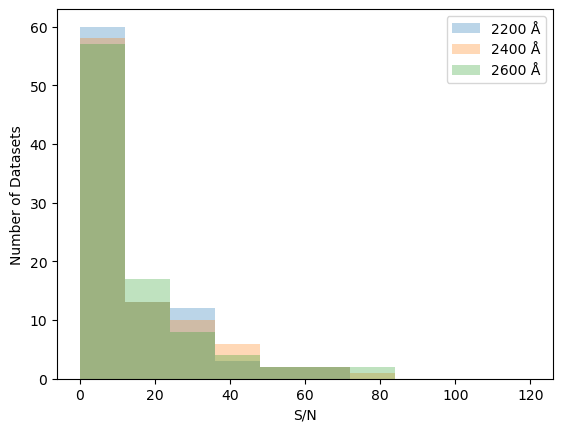

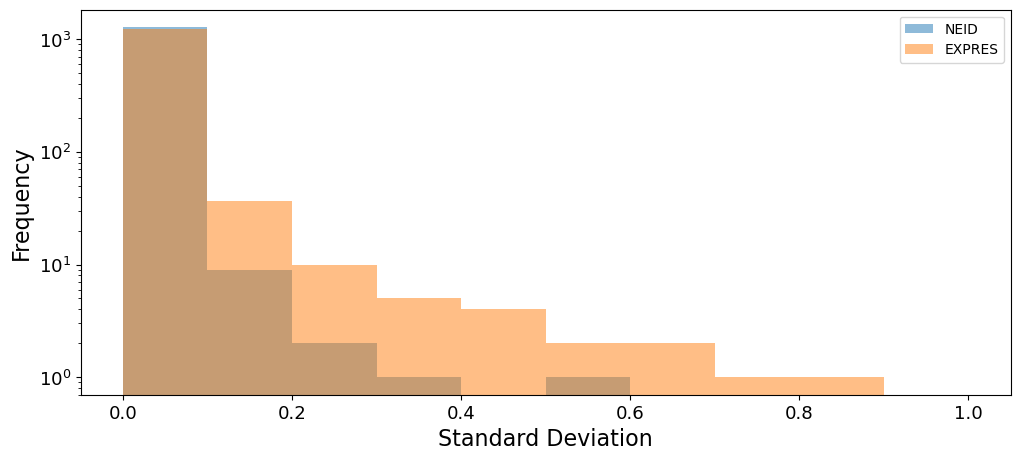

In [96]:

key='amps'
bins=np.arange(11)/10
plt.hist(stds_NEID[key].flatten(),alpha=0.5,label='NEID',bins=bins)
plt.hist(stds_EXPRES[key].flatten(),alpha=0.5,label='EXPRES',bins=bins)
plt.yscale('log')
plt.xlabel('Standard Deviation')
plt.ylabel('Frequency')
plt.legend()
plt.show()

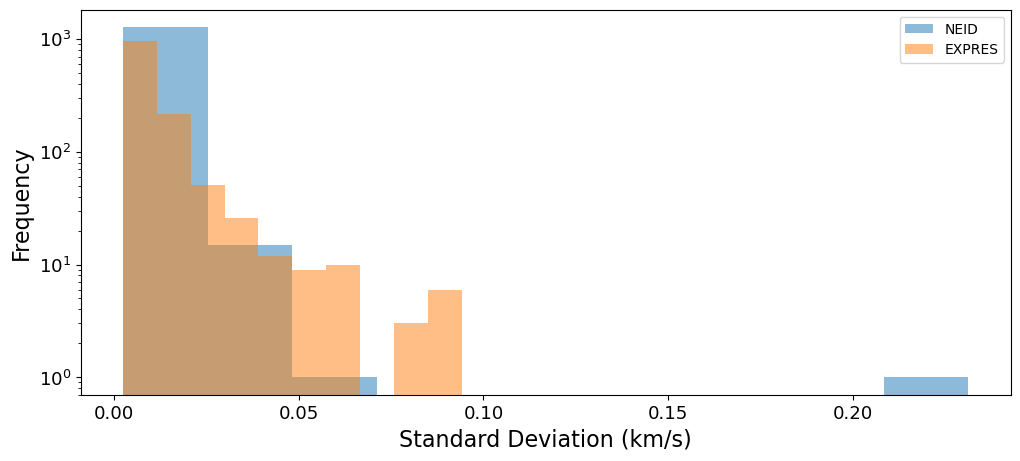

In [97]:

key='cens'
plt.hist(stds_NEID[key].flatten(),alpha=0.5,label='NEID')
plt.hist(stds_EXPRES[key].flatten(),alpha=0.5,label='EXPRES')
plt.yscale('log')
plt.xlabel('Standard Deviation (km/s)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

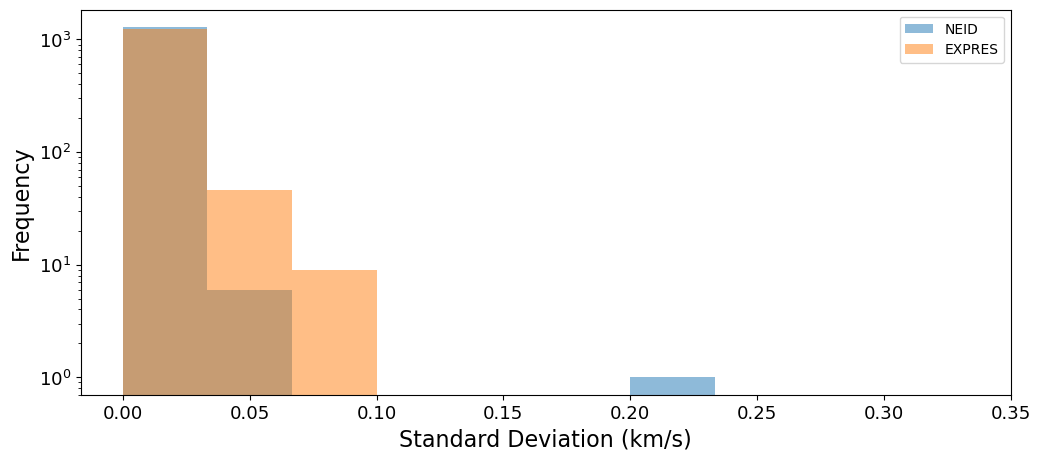

In [155]:
bins=np.arange(11)/30
key='cens'
plt.hist(stds_NEID[key].flatten(), bins=bins, alpha=0.5,label='NEID')
plt.hist(stds_EXPRES[key].flatten(), bins=bins, alpha=0.5,label='EXPRES')
plt.yscale('log')
plt.xlabel('Standard Deviation (km/s)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

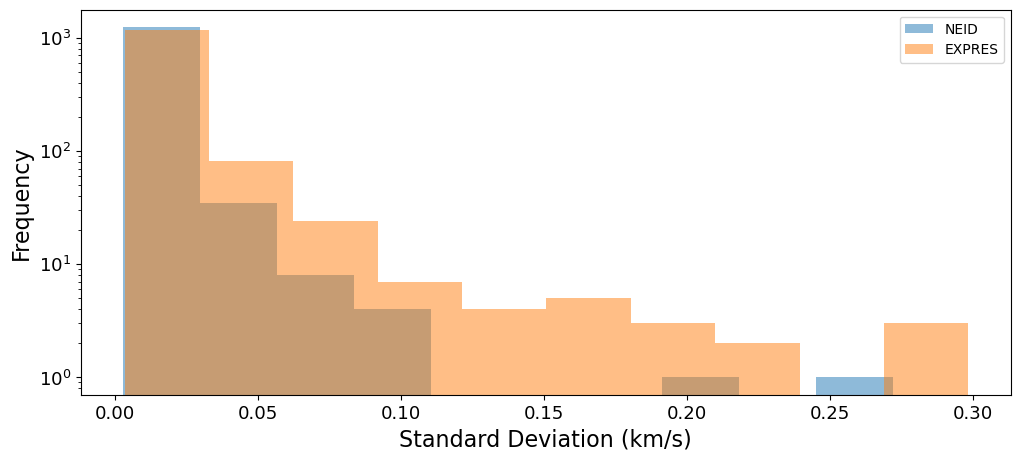

In [98]:

key='wids'
plt.hist(stds_NEID[key].flatten(),alpha=0.5,label='NEID')
plt.hist(stds_EXPRES[key].flatten(),alpha=0.5,label='EXPRES')
plt.yscale('log')
plt.xlabel('Standard Deviation (km/s)')
plt.ylabel('Frequency')
plt.legend()
plt.show()

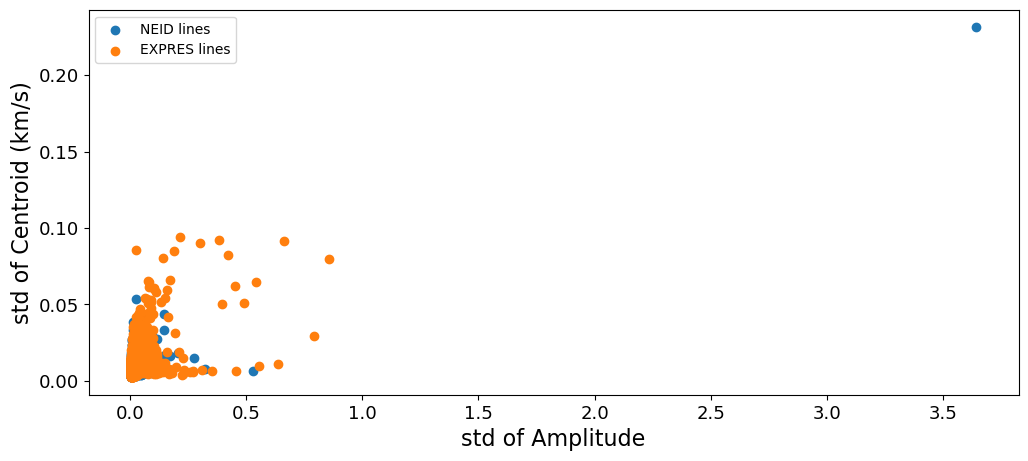

In [99]:
plt.scatter(stds_NEID['amps'].flatten(), stds_NEID['cens'].flatten(),label='NEID lines')
plt.scatter(stds_EXPRES['amps'].flatten(), stds_EXPRES['cens'].flatten(),label='EXPRES lines')
plt.xlabel('std of Amplitude')
plt.ylabel('std of Centroid (km/s)')
plt.legend()

(0.0, 0.15)

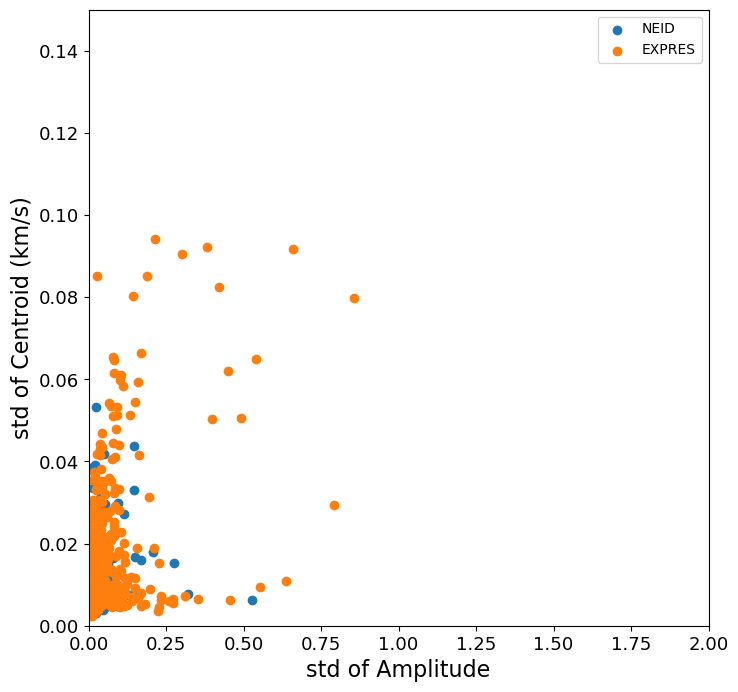

In [100]:
plt.figure(figsize=(8, 8))
plt.scatter(stds_NEID['amps'].flatten(), stds_NEID['cens'].flatten(),label='NEID')
plt.scatter(stds_EXPRES['amps'].flatten(), stds_EXPRES['cens'].flatten(),label='EXPRES')
plt.xlabel('std of Amplitude')
plt.ylabel('std of Centroid (km/s)')
plt.legend()
plt.xlim(0,2)
plt.ylim(0,.15)

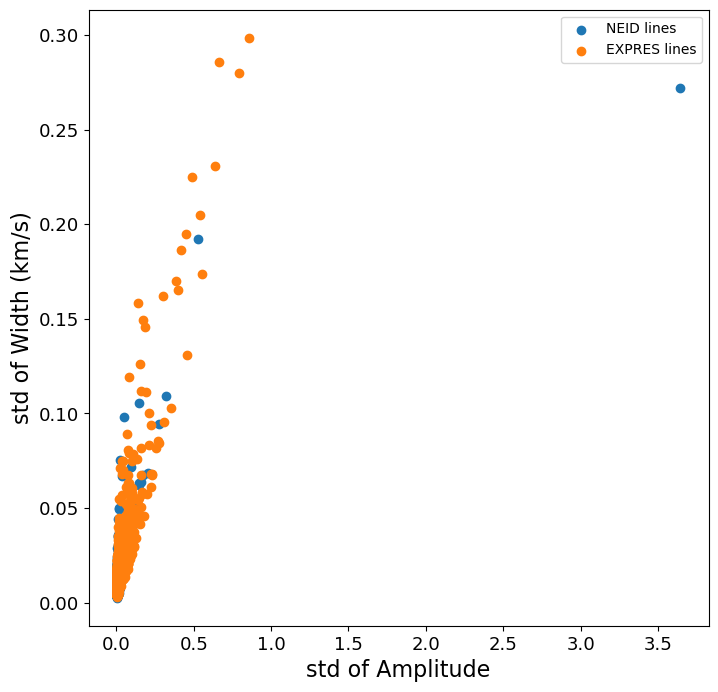

In [101]:
plt.figure(figsize=(8, 8))
plt.scatter(stds_NEID['amps'].flatten(), stds_NEID['wids'].flatten(),label='NEID lines')
plt.scatter(stds_EXPRES['amps'].flatten(), stds_EXPRES['wids'].flatten(),label='EXPRES lines')
plt.xlabel('std of Amplitude')
plt.ylabel('std of Width (km/s)')
plt.legend()

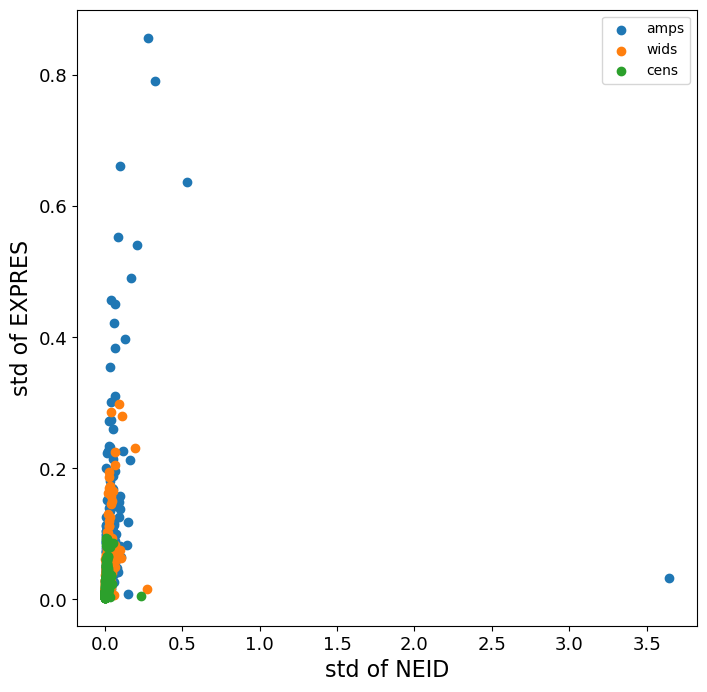

In [102]:
plt.figure(figsize=(8, 8))
plt.scatter(stds_NEID['amps'].flatten(), stds_EXPRES['amps'].flatten(),label='amps')
plt.scatter(stds_NEID['wids'].flatten(), stds_EXPRES['wids'].flatten(),label='wids')
plt.scatter(stds_NEID['cens'].flatten(), stds_EXPRES['cens'].flatten(),label='cens')
plt.xlabel('std of NEID')
plt.ylabel('std of EXPRES')
plt.legend()

(0.0, 2.0)

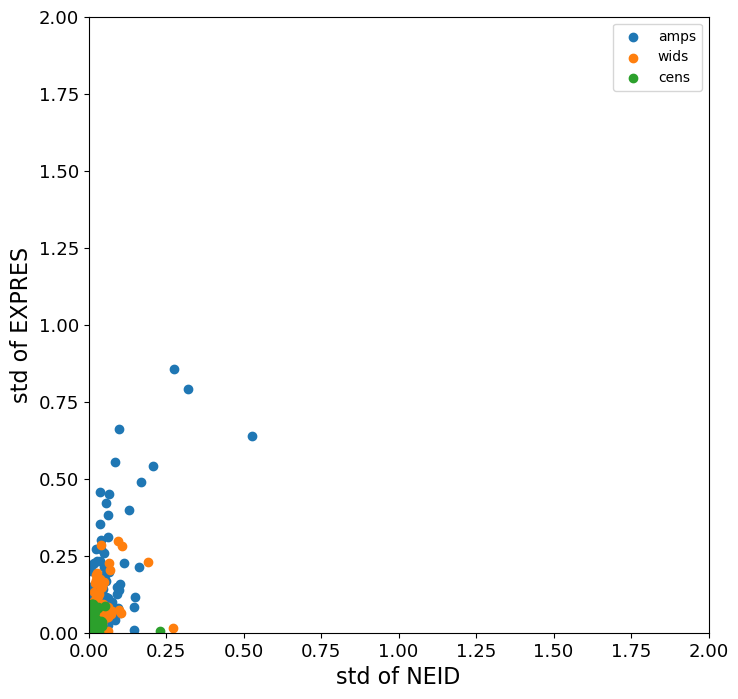

In [103]:
plt.figure(figsize=(8, 8))
plt.scatter(stds_NEID['amps'].flatten(), stds_EXPRES['amps'].flatten(),label='amps')
plt.scatter(stds_NEID['wids'].flatten(), stds_EXPRES['wids'].flatten(),label='wids')
plt.scatter(stds_NEID['cens'].flatten(), stds_EXPRES['cens'].flatten(),label='cens')
plt.xlabel('std of NEID')
plt.ylabel('std of EXPRES')
plt.legend()
plt.xlim(0,2)   
plt.ylim(0,2)   

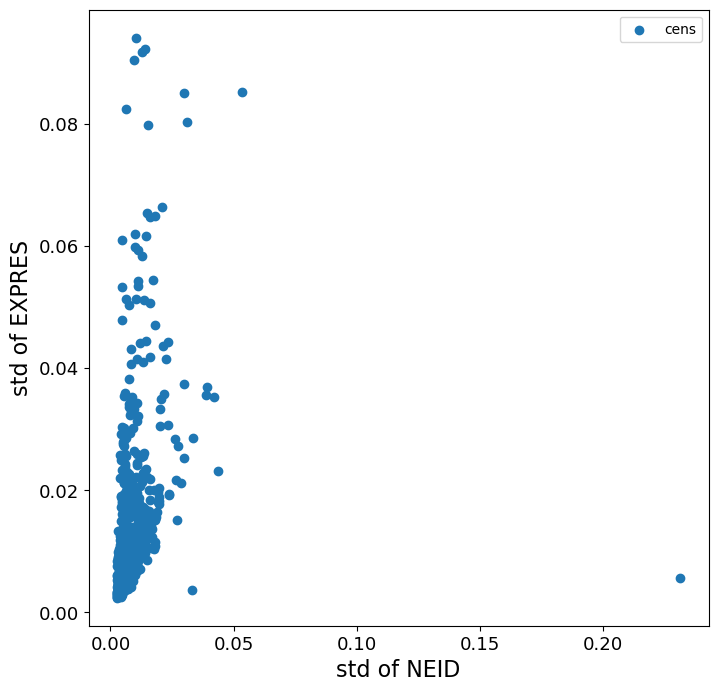

In [104]:
plt.figure(figsize=(8, 8))
plt.scatter(stds_NEID['cens'].flatten(), stds_EXPRES['cens'].flatten(),label='cens')
plt.xlabel('std of NEID')
plt.ylabel('std of EXPRES')
plt.legend()
#plt.xlim(0,2)   
#plt.ylim(0,2)   

(0.0, 1.0)

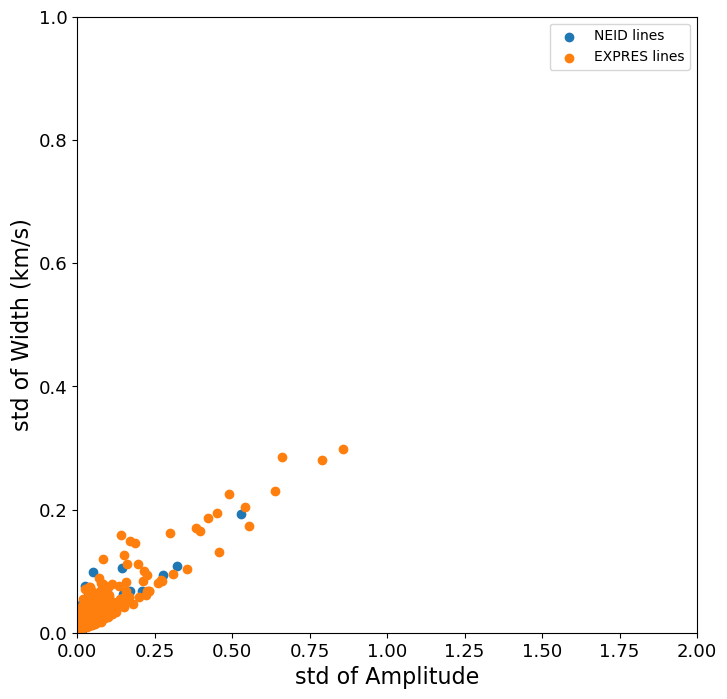

In [105]:

plt.figure(figsize=(8, 8))
plt.scatter(stds_NEID['amps'].flatten(), stds_NEID['wids'].flatten(),label='NEID lines')
plt.scatter(stds_EXPRES['amps'].flatten(), stds_EXPRES['wids'].flatten(),label='EXPRES lines')
plt.xlabel('std of Amplitude')
plt.ylabel('std of Width (km/s)')
plt.legend()
plt.xlim(0,2)
plt.ylim(0,1)

In [106]:
corrs={}
for key in stds_NEID:
    corrs[key] = np.zeros(len(line_measurements_NEID[key]))
    for i, line in enumerate(line_measurements_NEID[key]):

        neid_arr=line_measurements_NEID[key][i]
        expres_arr=line_measurements_EXPRES[key][i]
        nans_neid = np.isnan(neid_arr)
        nans_expres = np.isnan(expres_arr)
        #remove any NaN values for either array
        neid_arr = neid_arr[~nans_neid & ~nans_expres ]
        expres_arr = expres_arr[~nans_expres & ~nans_neid]
        corrs[key][i] = np.corrcoef(neid_arr.flatten(), expres_arr.flatten())[0, 1]

In [107]:
corrs

{'amps': array([ 0.08905736, -0.19247681,  0.2274579 , ...,  0.05469394,
         0.1613698 , -0.06378669], shape=(1292,)),
 'cens': array([ 0.02489588,  0.10573524, -0.19676139, ...,  0.05789893,
         0.07078609, -0.04878815], shape=(1292,)),
 'wids': array([ 0.05186256, -0.16459047, -0.07078753, ...,  0.08949642,
         0.15610792, -0.01560216], shape=(1292,))}

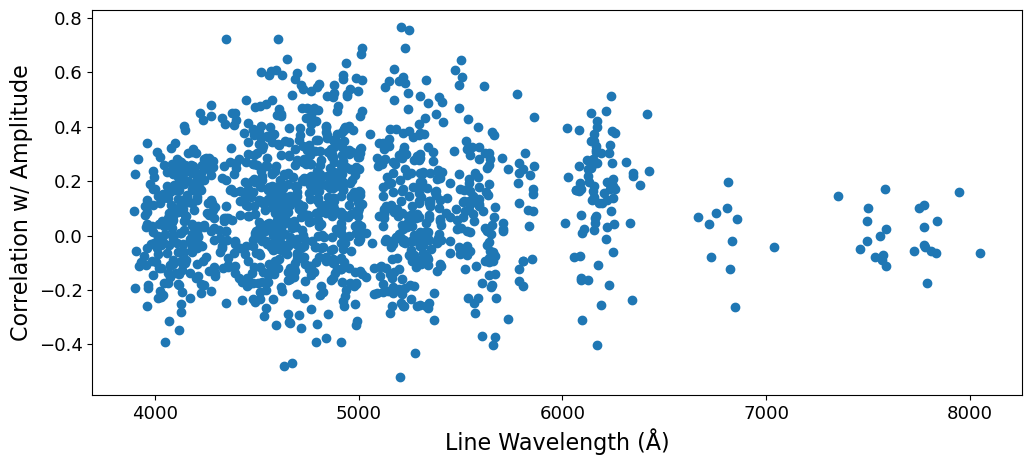

In [108]:
plt.scatter(good_line_wls, corrs['amps'])
plt.xlabel('Line Wavelength (Å)')
plt.ylabel('Correlation w/ Amplitude')
plt.show()  


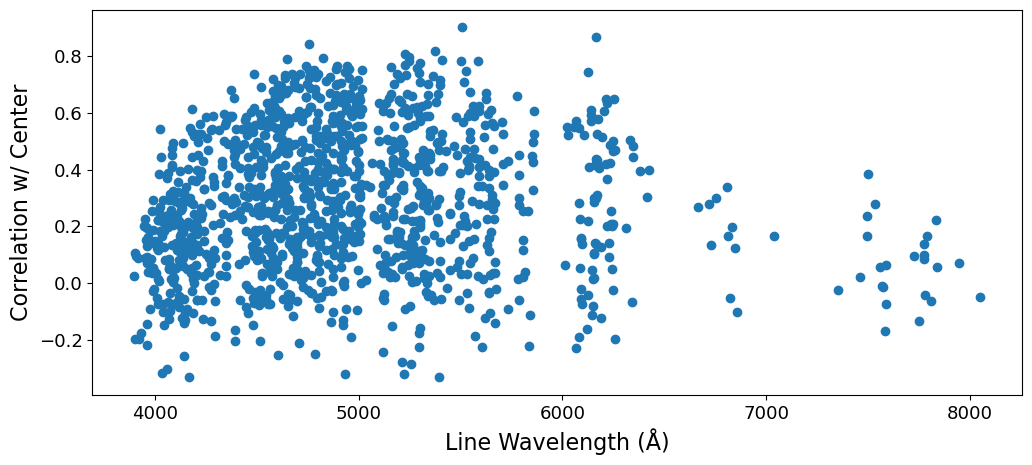

In [109]:
plt.scatter(good_line_wls, corrs['cens'])
plt.xlabel('Line Wavelength (Å)')
plt.ylabel('Correlation w/ Center')
plt.show()  

In [110]:
corrs_w_uncs={}
for key in stds_NEID:
    corrs_w_uncs[key] = np.zeros(len(line_measurements_NEID[key]))
    corrs_w_uncs[key+'_unc'] = np.zeros(len(line_measurements_NEID[key]))
    for i, line in enumerate(line_measurements_NEID[key]):

        neid_arr=line_measurements_NEID[key][i]
        expres_arr=line_measurements_EXPRES[key][i]
        nans_neid = np.isnan(neid_arr)
        nans_expres = np.isnan(expres_arr)
        #remove any NaN values for either array
        neid_arr = neid_arr[~nans_neid & ~nans_expres ]
        expres_arr = expres_arr[~nans_expres & ~nans_neid]
        neid_unc_arr = line_measurements_NEID[key[:-1]+'_errs'][i]
        expres_unc_arr = line_measurements_EXPRES[key[:-1]+'_errs'][i]
        neid_unc_arr = neid_unc_arr[~nans_neid & ~nans_expres ]
        expres_unc_arr = expres_unc_arr[~nans_expres & ~nans_neid]

        corr_temps=[]
        for n in range(1000):
            
            # Bootstrap resampling
            indices = np.random.choice(len(neid_arr), size=len(neid_arr), replace=True)
            neid_boot = neid_arr[indices]
            expres_boot = expres_arr[indices]
            corr_temps.append(np.corrcoef(neid_boot.flatten(), expres_boot.flatten())[0, 1])

        corrs_w_uncs[key][i] = np.corrcoef(neid_arr.flatten(), expres_arr.flatten())[0, 1]
        corrs_w_uncs[key+'_unc'][i] = np.std(corr_temps)

In [111]:
len(line_measurements_NEID[key])

1292

In [112]:
corrs_w_uncs_mc={}
for key in stds_NEID:
    corrs_w_uncs_mc[key] = np.zeros(len(line_measurements_NEID[key]))
    corrs_w_uncs_mc[key+'_unc'] = np.zeros(len(line_measurements_NEID[key]))
    for i in range(len(line_measurements_NEID[key])):

        neid_arr=line_measurements_NEID[key][i]
        expres_arr=line_measurements_EXPRES[key][i]
        nans_neid = np.isnan(neid_arr)
        nans_expres = np.isnan(expres_arr)
        #remove any NaN values for either array
        neid_arr = neid_arr[~nans_neid & ~nans_expres ]
        expres_arr = expres_arr[~nans_expres & ~nans_neid]
        neid_unc_arr = line_measurements_NEID[key[:-1]+'_errs'][i]
        expres_unc_arr = line_measurements_EXPRES[key[:-1]+'_errs'][i]
        neid_unc_arr = neid_unc_arr[~nans_neid & ~nans_expres ]
        expres_unc_arr = expres_unc_arr[~nans_expres & ~nans_neid]
        corrs_w_uncs_mc[key][i] = np.corrcoef(neid_arr.flatten(), expres_arr.flatten())[0, 1]
        corr_temps=[]
        for n in range(1000):
            #monte carlo sampling
            neid_temp=np.random.normal(loc=neid_arr, scale=neid_unc_arr)
            #print(len(neid_temp))
            expres_temp=np.random.normal(loc=expres_arr, scale=expres_unc_arr)
            corr_temps.append(np.corrcoef(neid_temp.flatten(), expres_temp.flatten())[0, 1])
        #print(corr_temps)
        std_temp = np.std(corr_temps)
        #print(std_temp)
        corrs_w_uncs_mc[key+'_unc'][i] = std_temp
        #print(corrs_w_uncs_mc[key+'_unc'][i])

In [113]:
corrs_w_uncs_mc
with open('corrs_w_uncs_mc.pkl','wb') as f:
    pickle.dump(corrs_w_uncs_mc,f)
with open('corrs_w_uncs.pkl','wb') as f:
    pickle.dump(corrs_w_uncs,f)

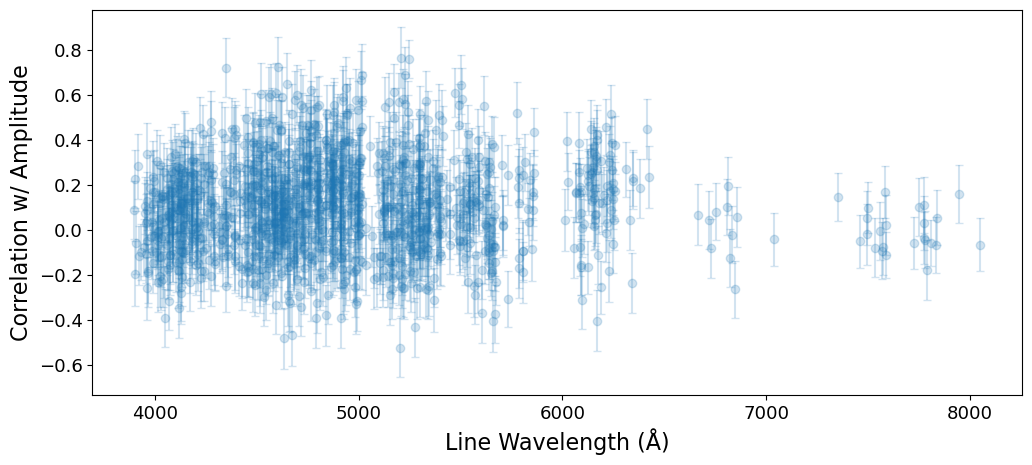

In [114]:
plt.errorbar(good_line_wls, corrs_w_uncs_mc['amps'], yerr=corrs_w_uncs_mc['amps_unc'], fmt='o',alpha=0.2)
plt.xlabel('Line Wavelength (Å)')
plt.ylabel('Correlation w/ Amplitude')
plt.show()  

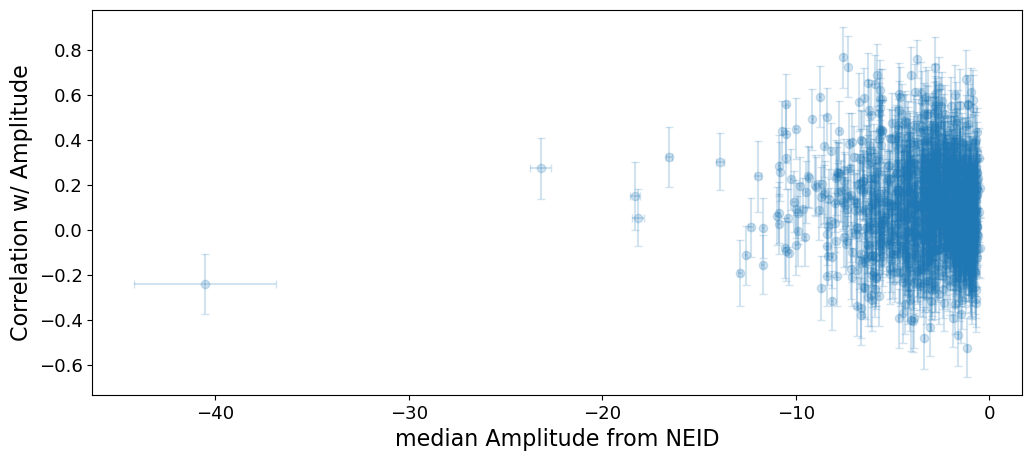

In [115]:
plt.errorbar(medians_NEID['amps'].flatten(), corrs_w_uncs_mc['amps'].flatten(), yerr=corrs_w_uncs_mc['amps_unc'].flatten(),
              xerr=stds_NEID['amps'].flatten(),
              fmt='o',alpha=0.2)
plt.xlabel('median Amplitude from NEID')
plt.ylabel('Correlation w/ Amplitude')
plt.show()  

(-20.0, 0.0)

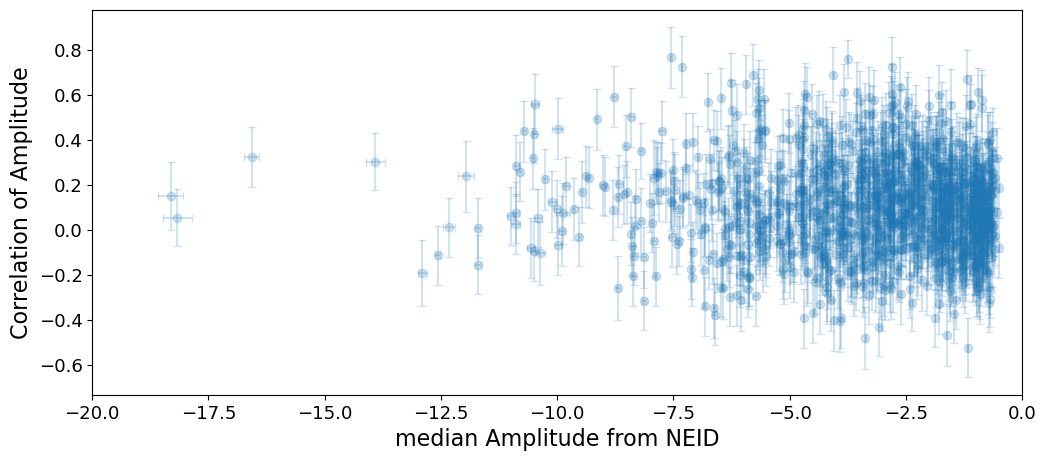

In [116]:
plt.errorbar(medians_NEID['amps'].flatten(), corrs_w_uncs_mc['amps'].flatten(), yerr=corrs_w_uncs_mc['amps_unc'].flatten(),
              xerr=stds_NEID['amps'].flatten(),
              fmt='o',alpha=0.2)
plt.xlabel('median Amplitude from NEID')
plt.ylabel('Correlation of Amplitude')
plt.xlim(-20,0)

In [117]:
stds_NEID['amps'].flatten().shape

(1292,)

In [118]:
print(corrs_w_uncs_mc['amps_unc'].shape,corrs_w_uncs_mc['amps'].shape,medians_NEID['amps'].shape)

(1292,) (1292,) (1292, 1)


Text(0, 0.5, 'Correlation of Amplitude')

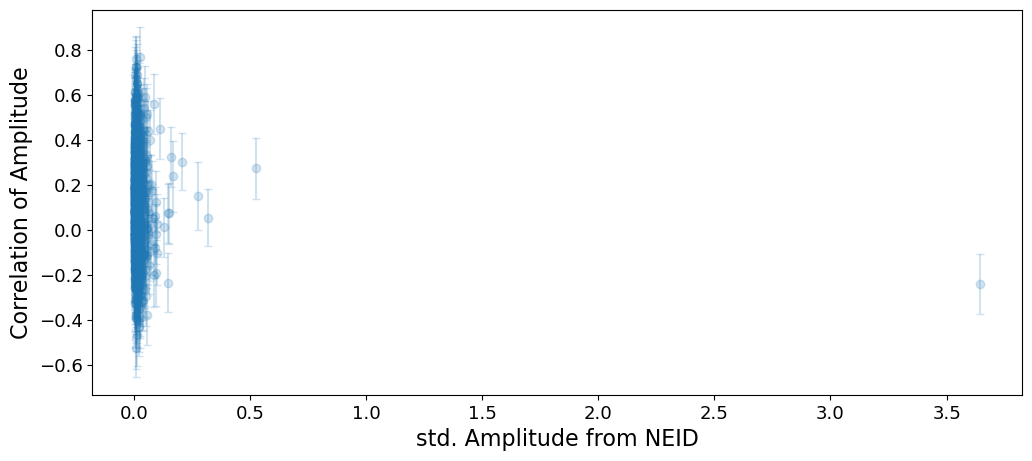

In [119]:
plt.errorbar(stds_NEID['amps'].flatten(), corrs_w_uncs_mc['amps'].flatten(), yerr=corrs_w_uncs_mc['amps_unc'].flatten(),
              fmt='o',alpha=0.2)
plt.xlabel('std. Amplitude from NEID')
plt.ylabel('Correlation of Amplitude')


Text(0, 0.5, 'Correlation')

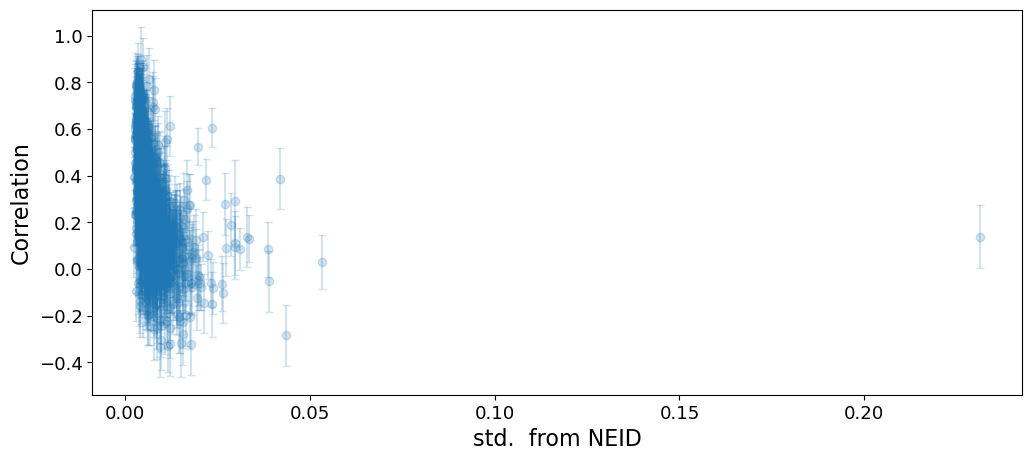

In [120]:
key='cens'
plt.errorbar(stds_NEID[key].flatten(), corrs_w_uncs_mc[key].flatten(), yerr=corrs_w_uncs_mc[key+'_unc'].flatten(),
              fmt='o',alpha=0.2)
plt.xlabel('std.  from NEID')
plt.ylabel('Correlation')


(-0.001, 0.05)

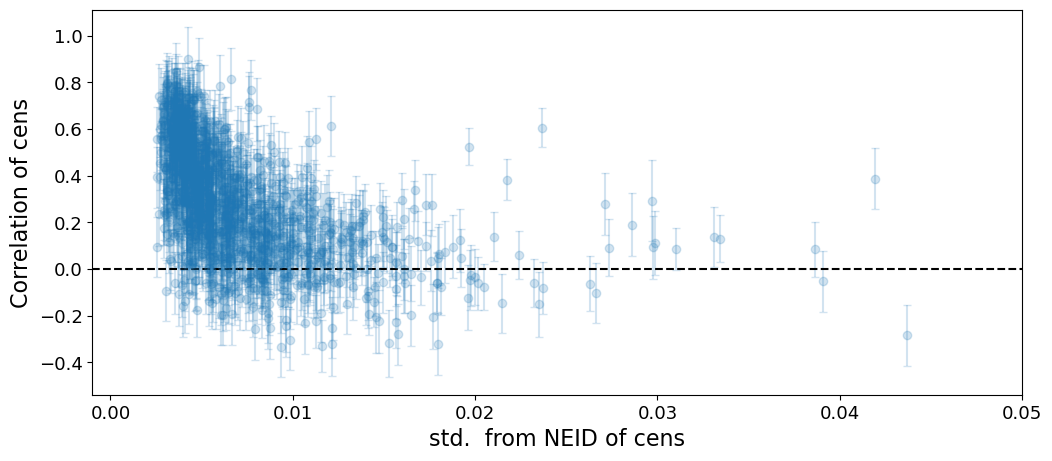

In [121]:
key='cens'
plt.errorbar(stds_NEID[key].flatten(), corrs_w_uncs_mc[key].flatten(), yerr=corrs_w_uncs_mc[key+'_unc'].flatten(),
              fmt='o',alpha=0.2)
plt.xlabel('std.  from NEID of '+key)
plt.ylabel('Correlation of '+key)
plt.hlines(0, -.001, .05, colors='k', linestyles='dashed')
plt.xlim(-.001,.05)

(-0.01, 0.3)

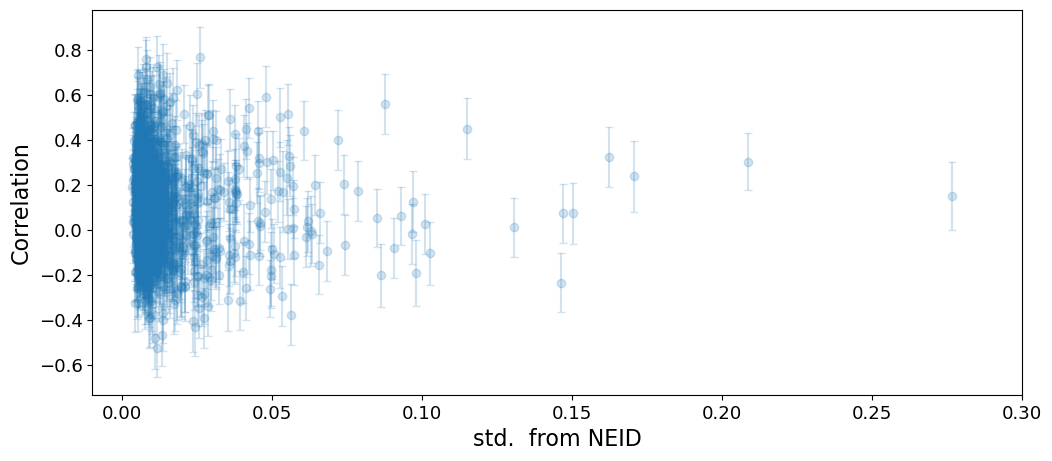

In [122]:
key='amps'
plt.errorbar(stds_NEID[key].flatten(), corrs_w_uncs_mc[key].flatten(), yerr=corrs_w_uncs_mc[key+'_unc'].flatten(),
              fmt='o',alpha=0.2)
plt.xlabel('std.  from NEID')
plt.ylabel('Correlation')
plt.xlim(-.01,.3)

(-0.01, 0.3)

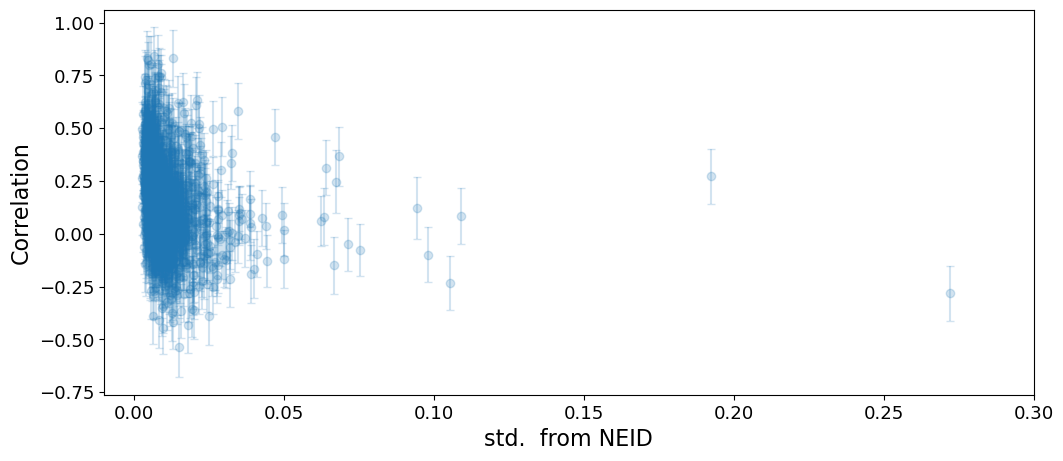

In [123]:
key='wids'
plt.errorbar(stds_NEID[key].flatten(), corrs_w_uncs_mc[key].flatten(), yerr=corrs_w_uncs_mc[key+'_unc'].flatten(),
              fmt='o',alpha=0.2)
plt.xlabel('std.  from NEID')
plt.ylabel('Correlation')
plt.xlim(-.01,.3)

Text(0, 0.5, 'Correlation of cens')

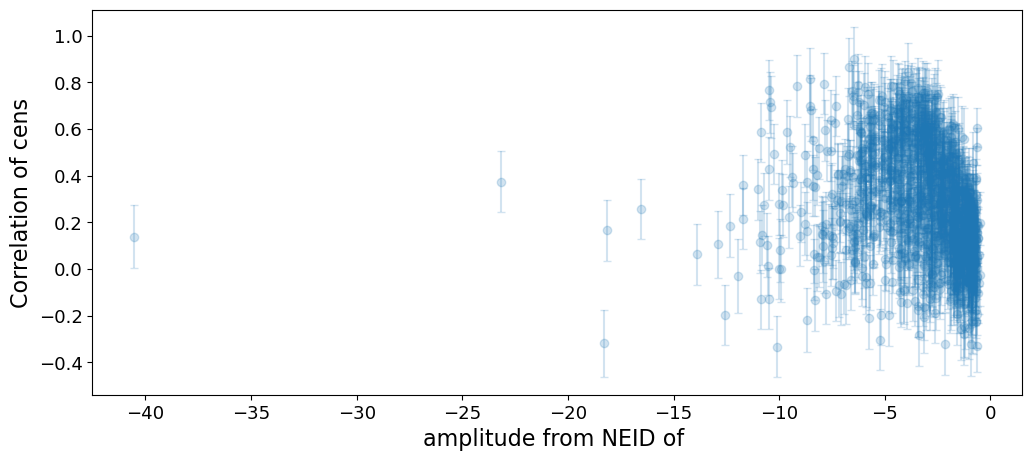

In [124]:
key='cens'
plt.errorbar(medians_NEID['amps'].flatten(), corrs_w_uncs_mc[key].flatten(), yerr=corrs_w_uncs_mc[key+'_unc'].flatten(),
              fmt='o',alpha=0.2)
plt.xlabel('amplitude from NEID of ')
plt.ylabel('Correlation of '+key)
#plt.xlim(-.001,.05)

(-20.0, 0.0)

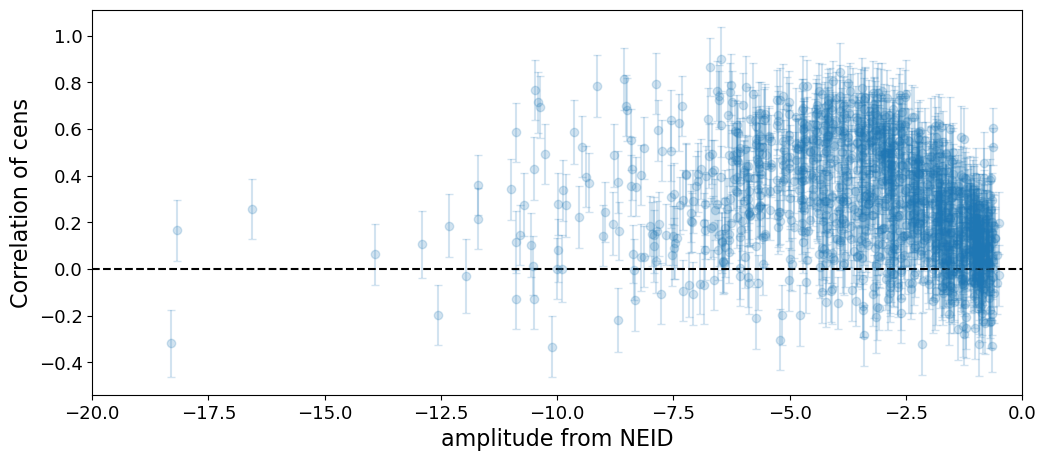

In [125]:
key='cens'
plt.errorbar(medians_NEID['amps'].flatten(), corrs_w_uncs_mc[key].flatten(), yerr=corrs_w_uncs_mc[key+'_unc'].flatten(),
              fmt='o',alpha=0.2)
plt.hlines(0, -20, 0, colors='k', linestyles='dashed')
plt.xlabel('amplitude from NEID')
plt.ylabel('Correlation of '+key)
plt.xlim(-20,0)

In [126]:
#calculate the correlation
correlation = np.corrcoef(medians_NEID['amps'].flatten(), corrs_w_uncs_mc['cens'].flatten())[0, 1]
correlation

np.float64(-0.20256262529424537)

(-0.001, 0.05)

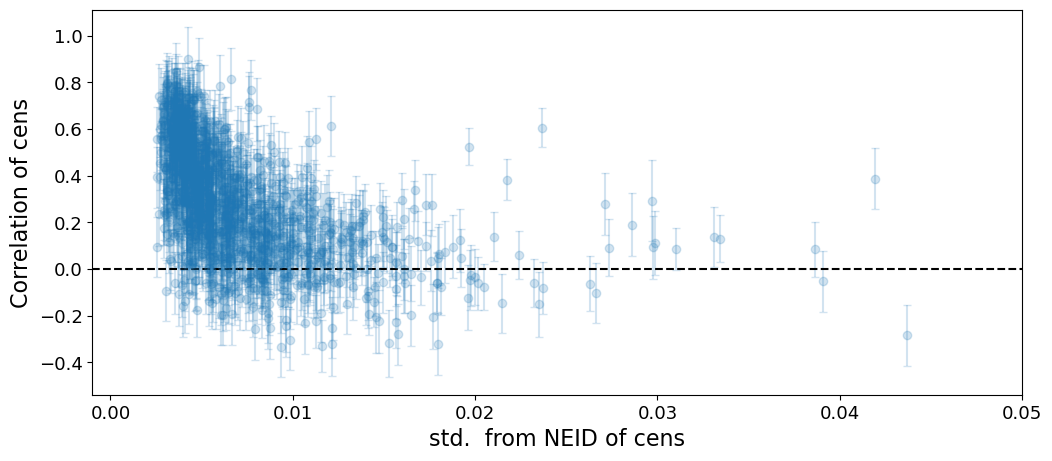

In [127]:
key='cens'
plt.errorbar(stds_NEID[key].flatten(), corrs_w_uncs_mc[key].flatten(), yerr=corrs_w_uncs_mc[key+'_unc'].flatten(),
              fmt='o',alpha=0.2)
plt.xlabel('std.  from NEID of '+key)
plt.ylabel('Correlation of '+key)
plt.hlines(0, -.001, .05, colors='k', linestyles='dashed')
plt.xlim(-.001,.05)

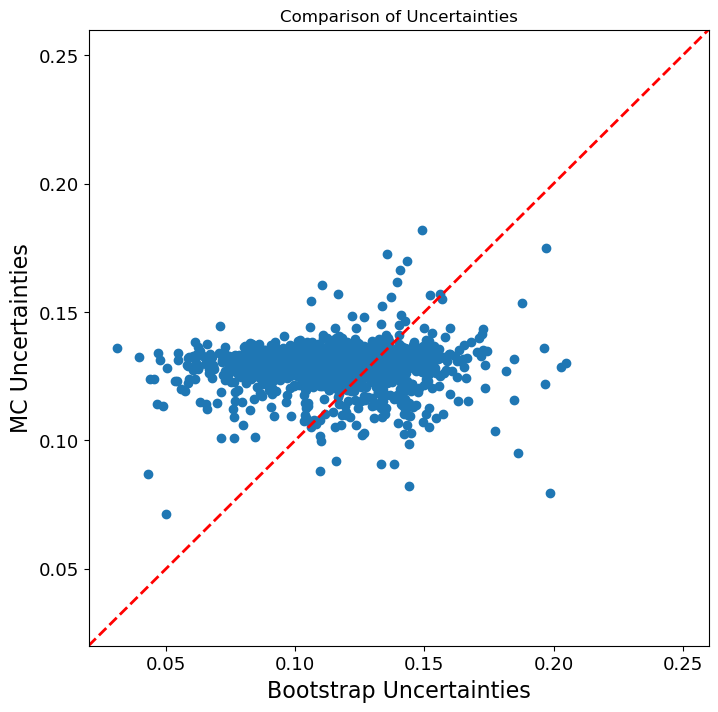

In [128]:
#compare uncs from MC to bootstrap
plt.figure(figsize=(8, 8))
plt.scatter(corrs_w_uncs['cens_unc'].flatten(), corrs_w_uncs_mc['cens_unc'].flatten())
plt.xlabel('Bootstrap Uncertainties')
plt.ylabel('MC Uncertainties')
plt.title('Comparison of Uncertainties')
plt.xlim(0.02,.26)
plt.ylim(0.02,.26)
#plot x=y line
plt.plot([0.02, 0.26], [0.02, 0.26], 'r--', lw=2)
plt.show()

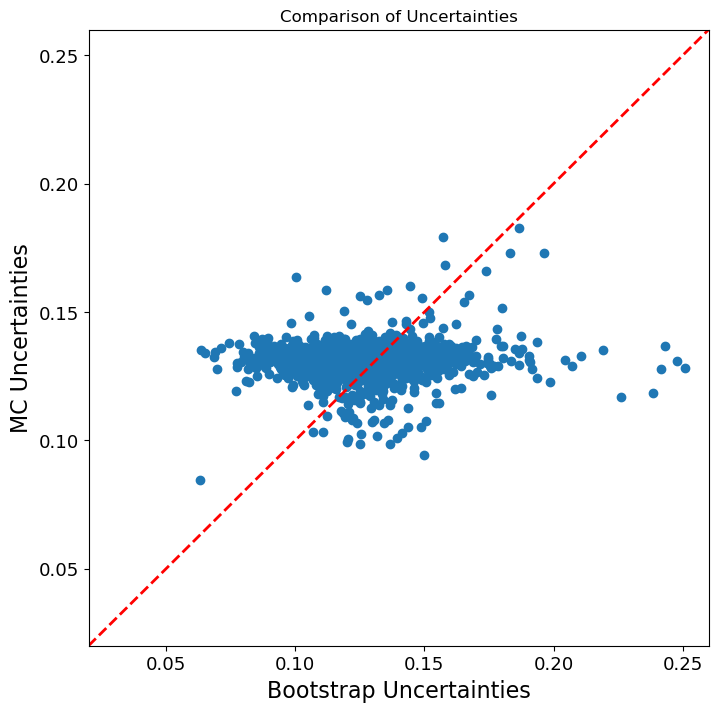

In [129]:
#compare uncs from MC to bootstrap
plt.figure(figsize=(8, 8))
plt.scatter(corrs_w_uncs['amps_unc'].flatten(), corrs_w_uncs_mc['amps_unc'].flatten())
plt.xlabel('Bootstrap Uncertainties')
plt.ylabel('MC Uncertainties')
plt.title('Comparison of Uncertainties')
plt.xlim(0.02,.26)
plt.ylim(0.02,.26)
#plot x=y line
plt.plot([0.02, 0.26], [0.02, 0.26], 'r--', lw=2)
plt.show()

(-0.001, 0.05)

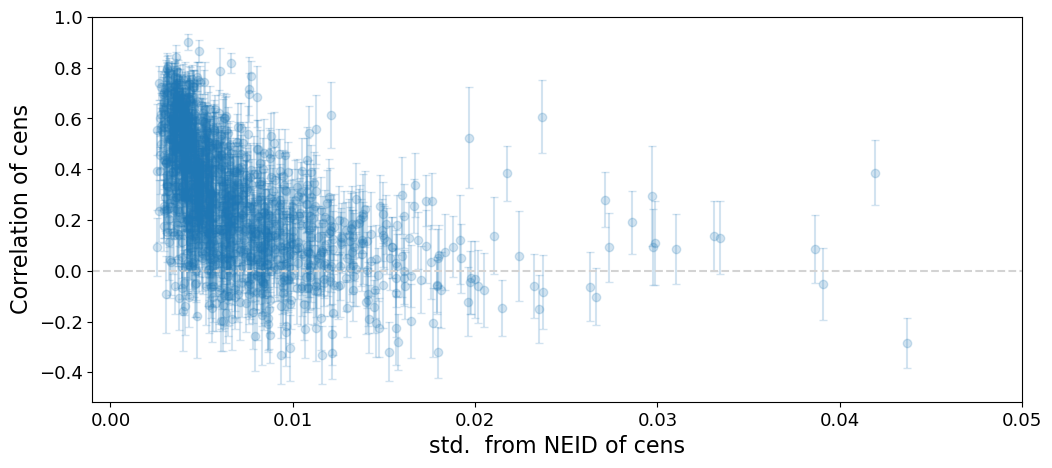

In [130]:
key='cens'
plt.errorbar(stds_NEID[key].flatten(), corrs_w_uncs[key].flatten(), yerr=corrs_w_uncs[key+'_unc'].flatten(),
              fmt='o',alpha=0.2)
plt.xlabel('std.  from NEID of '+key)
plt.ylabel('Correlation of '+key)
plt.hlines(0, -.001, .05, colors='lightgray', linestyles='dashed')
plt.xlim(-.001,.05)
#plot lines at x=.01, and y=0.4
#plt.vlines(0.01, -0.6, 0.9, colors='k', linestyles=':')#
#plt.hlines(0.4, -0.1, 0.1, colors='k', linestyles=':')

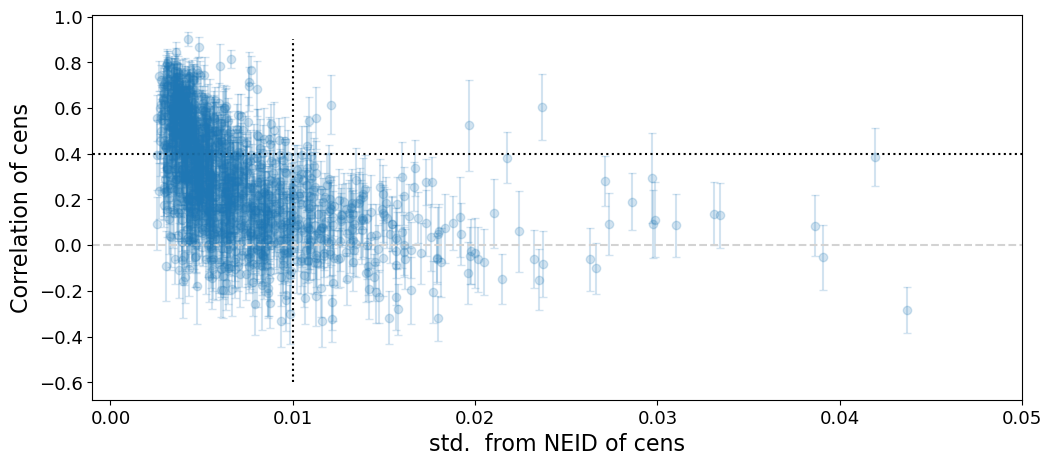

In [131]:
key='cens'
plt.errorbar(stds_NEID[key].flatten(), corrs_w_uncs[key].flatten(), yerr=corrs_w_uncs[key+'_unc'].flatten(),
              fmt='o',alpha=0.2)
plt.xlabel('std.  from NEID of '+key)
plt.ylabel('Correlation of '+key)
plt.hlines(0, -.001, .05, colors='lightgray', linestyles='dashed')
plt.xlim(-.001,.05)
#plot lines at x=.01, and y=0.4
plt.vlines(0.01, -0.6, 0.9, colors='k', linestyles=':')
plt.hlines(0.4, -0.1, 0.1, colors='k', linestyles=':')

In [132]:
low_s2n=stds_NEID[key].flatten() > 0.01
high_s2n=stds_NEID[key].flatten() <= 0.01
high_variability=(stds_NEID[key].flatten() > 0.01) & (corrs_w_uncs_mc['cens'].flatten() >= .4)
high_corr=(stds_NEID[key].flatten() <= 0.01) & (corrs_w_uncs_mc['cens'].flatten() >= .4)

low_corr=(stds_NEID[key].flatten() <= 0.01) & (corrs_w_uncs_mc['cens'].flatten() < .4)

high_depth=(good_line_depths >= .6) & (stds_NEID['cens'].flatten() <= 0.01)
low_depth=(good_line_depths < .6) & (stds_NEID['cens'].flatten() <= 0.01)

depth_p2_p4=(good_line_depths >= 0.2) & (good_line_depths < 0.4) & (stds_NEID['cens'].flatten() <= 0.01)
depth_p4_p6=(good_line_depths >= 0.4) & (good_line_depths < 0.6) & (stds_NEID['cens'].flatten() <= 0.01)

(-0.001, 0.05)

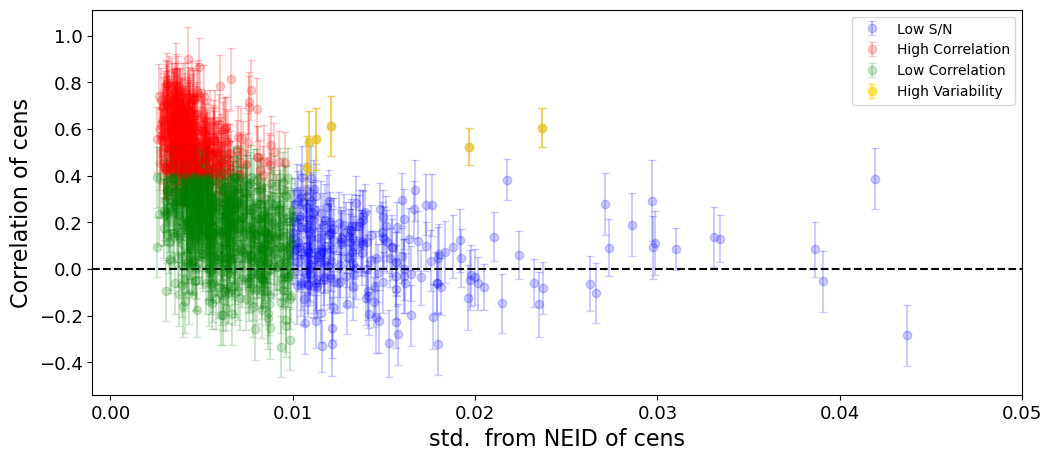

In [133]:
key='cens'
#plot low s2n
plt.errorbar(stds_NEID[key].flatten()[low_s2n], corrs_w_uncs_mc[key].flatten()[low_s2n], 
             yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[low_s2n],
              fmt='o',alpha=0.2,color='blue',label='Low S/N')
#plot high correlation
plt.errorbar(stds_NEID[key].flatten()[high_corr], corrs_w_uncs_mc[key].flatten()[high_corr], 
             yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[high_corr],
              fmt='o',alpha=0.2,color='red',label='High Correlation')
#plot low correlation
plt.errorbar(stds_NEID[key].flatten()[low_corr], corrs_w_uncs_mc[key].flatten()[low_corr], 
             yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[low_corr],
              fmt='o',alpha=0.2,color='green',label='Low Correlation')
#plot high variability
plt.errorbar(stds_NEID[key].flatten()[high_variability], corrs_w_uncs_mc[key].flatten()[high_variability], 
             yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[high_variability],
              fmt='o',alpha=0.6,color='gold',label='High Variability')
plt.legend()
plt.xlabel('std.  from NEID of '+key)
plt.ylabel('Correlation of '+key)
plt.hlines(0, -.001, .05, colors='k', linestyles='dashed')
plt.xlim(-.001,.05)

(-0.001, 0.05)

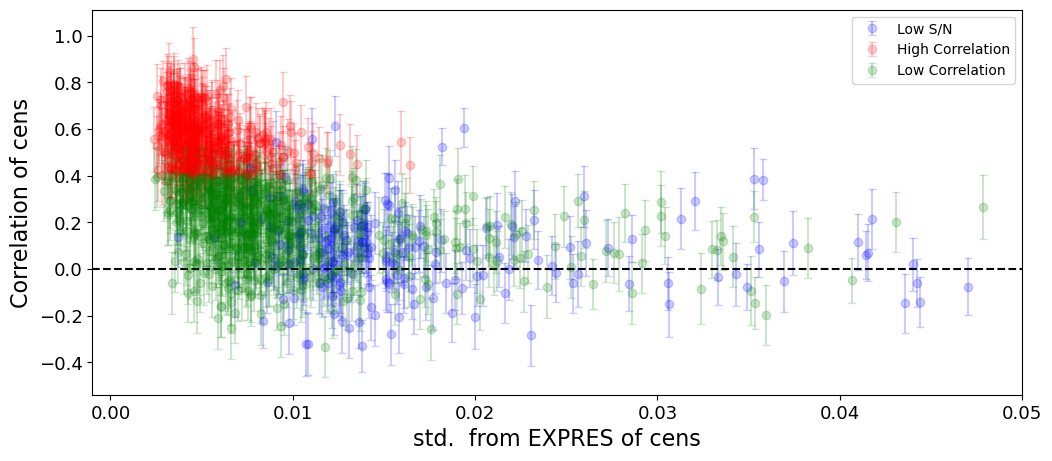

In [134]:
key='cens'
#plot low s2n
plt.errorbar(stds_EXPRES[key].flatten()[low_s2n], corrs_w_uncs_mc[key].flatten()[low_s2n], 
             yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[low_s2n],
              fmt='o',alpha=0.2,color='blue',label='Low S/N')
#plot high correlation
plt.errorbar(stds_EXPRES[key].flatten()[high_corr], corrs_w_uncs_mc[key].flatten()[high_corr], 
             yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[high_corr],
              fmt='o',alpha=0.2,color='red',label='High Correlation')
#plot low correlation
plt.errorbar(stds_EXPRES[key].flatten()[low_corr], corrs_w_uncs_mc[key].flatten()[low_corr], 
             yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[low_corr],
              fmt='o',alpha=0.2,color='green',label='Low Correlation')
plt.legend()
plt.xlabel('std.  from EXPRES of '+key)
plt.ylabel('Correlation of '+key)
plt.hlines(0, -.001, .05, colors='k', linestyles='dashed')
plt.xlim(-.001,.05)

(-20.0, 0.0)

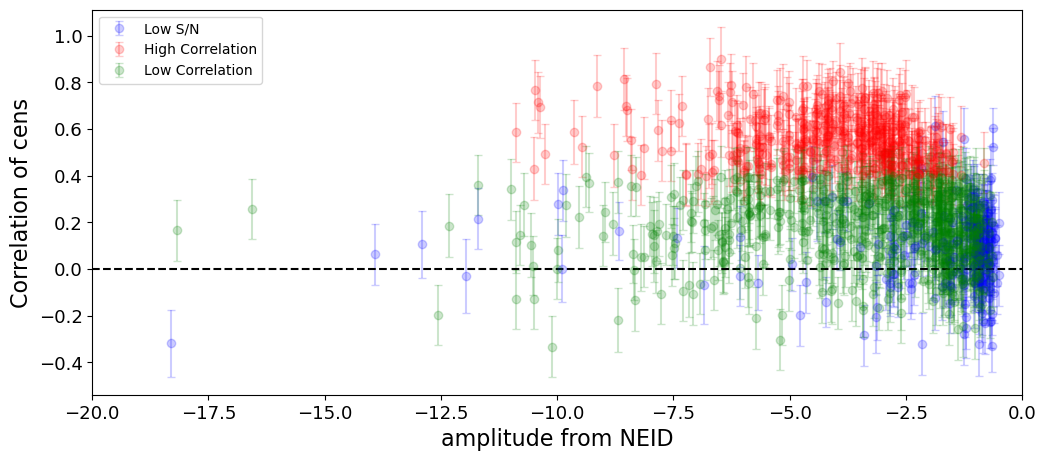

In [135]:
key='cens'
#plot low s2n
plt.errorbar(medians_NEID['amps'].flatten()[low_s2n], corrs_w_uncs_mc[key].flatten()[low_s2n],
              yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[low_s2n],
              fmt='o',alpha=0.2,color='blue',label='Low S/N')
#plot high correlation
plt.errorbar(medians_NEID['amps'].flatten()[high_corr], corrs_w_uncs_mc[key].flatten()[high_corr],
              yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[high_corr],
              fmt='o',alpha=0.2,color='red',label='High Correlation')
#plot low correlation
plt.errorbar(medians_NEID['amps'].flatten()[low_corr], corrs_w_uncs_mc[key].flatten()[low_corr],
              yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[low_corr],
              fmt='o',alpha=0.2,color='green',label='Low Correlation')
plt.legend()
plt.hlines(0, -20, 0, colors='k', linestyles='dashed')
plt.xlabel('amplitude from NEID')
plt.ylabel('Correlation of '+key)
plt.xlim(-20,0)

(-20.0, 0.0)

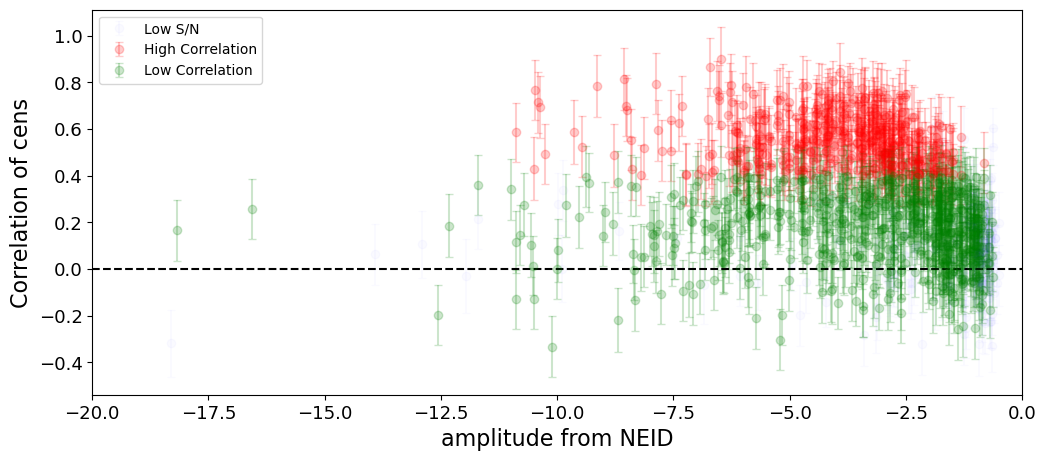

In [136]:
key='cens'
#plot low s2n
plt.errorbar(medians_NEID['amps'].flatten()[low_s2n], corrs_w_uncs_mc[key].flatten()[low_s2n],
              yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[low_s2n],
              fmt='o',alpha=0.02,color='blue',label='Low S/N')
#plot high correlation
plt.errorbar(medians_NEID['amps'].flatten()[high_corr], corrs_w_uncs_mc[key].flatten()[high_corr],
              yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[high_corr],
              fmt='o',alpha=0.2,color='red',label='High Correlation')
#plot low correlation
plt.errorbar(medians_NEID['amps'].flatten()[low_corr], corrs_w_uncs_mc[key].flatten()[low_corr],
              yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[low_corr],
              fmt='o',alpha=0.2,color='green',label='Low Correlation')
plt.legend()
plt.hlines(0, -20, 0, colors='k', linestyles='dashed')
plt.xlabel('amplitude from NEID')
plt.ylabel('Correlation of '+key)
plt.xlim(-20,0)

-0.16594500745006224


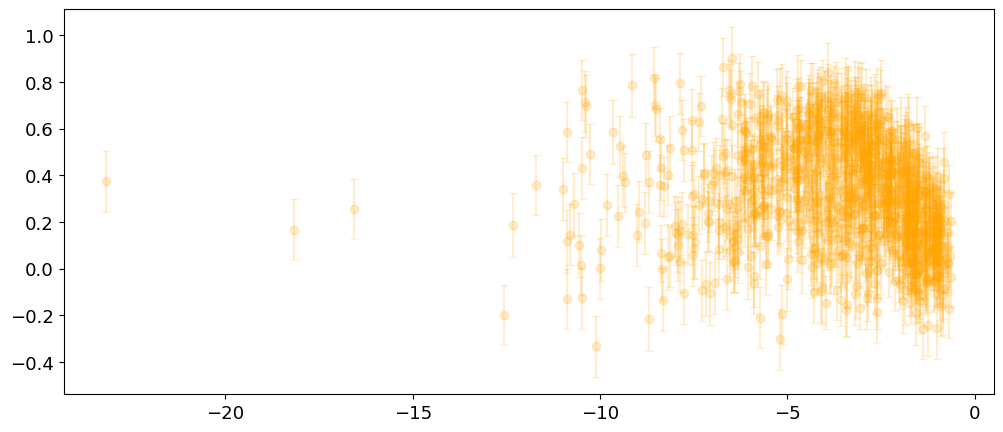

In [137]:
#plot high s2n
plt.errorbar(medians_NEID['amps'].flatten()[high_s2n], corrs_w_uncs_mc[key].flatten()[high_s2n],
              yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[high_s2n],
              fmt='o',alpha=0.2,color='orange',label='High S/N')

correlation = np.corrcoef(medians_NEID['amps'].flatten()[high_s2n], corrs_w_uncs_mc['cens'].flatten()[high_s2n])[0, 1]
print(correlation)

Text(0.5, 1.0, 'NEID Amplitude vs Line Depth')

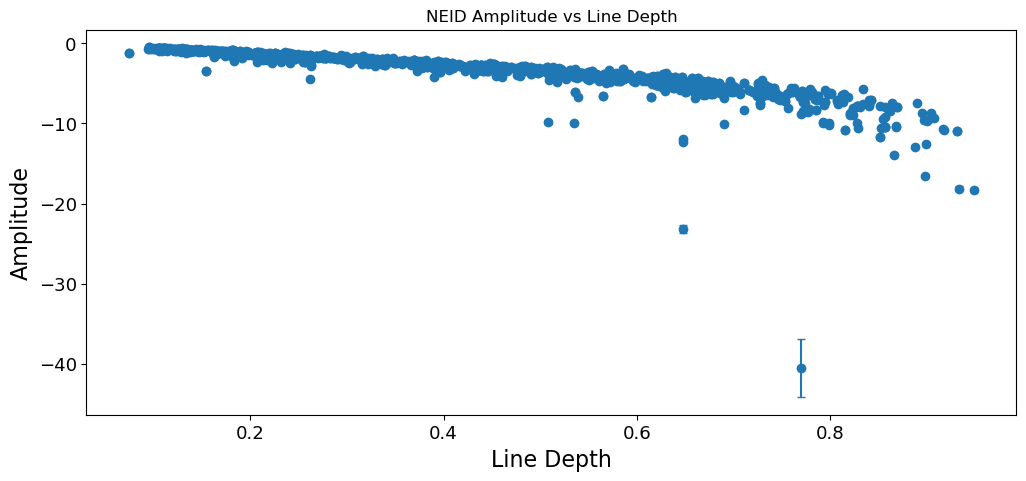

In [138]:
plt.errorbar(good_line_depths, medians_NEID['amps'].flatten(), yerr=stds_NEID['amps'].flatten(), fmt='o')
plt.xlabel('Line Depth')
plt.ylabel('Amplitude')
plt.title('NEID Amplitude vs Line Depth')


(-20.0, 0.0)

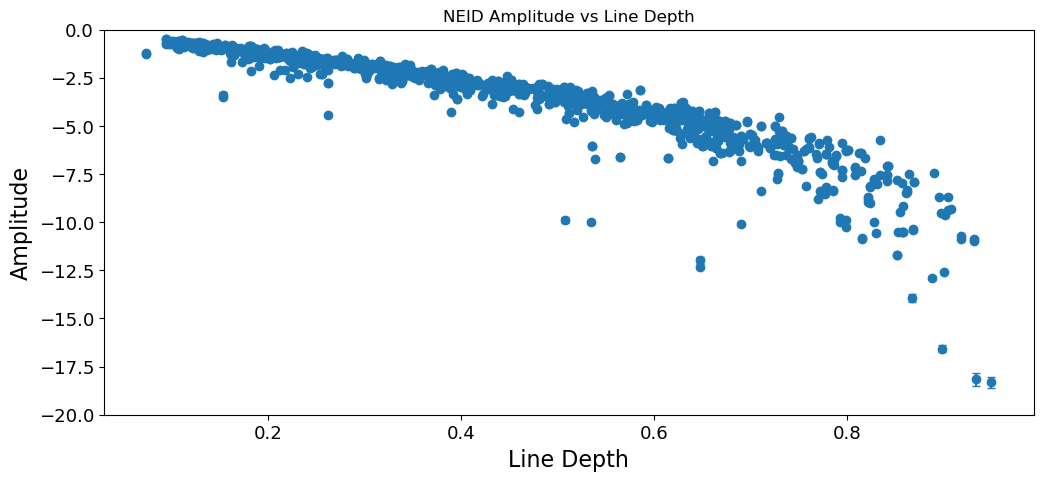

In [139]:
plt.errorbar(good_line_depths, medians_NEID['amps'].flatten(), yerr=stds_NEID['amps'].flatten(), fmt='o')
plt.xlabel('Line Depth')
plt.ylabel('Amplitude')
plt.title('NEID Amplitude vs Line Depth')
plt.ylim(-20,0)

Text(0, 0.5, 'Width Correlations')

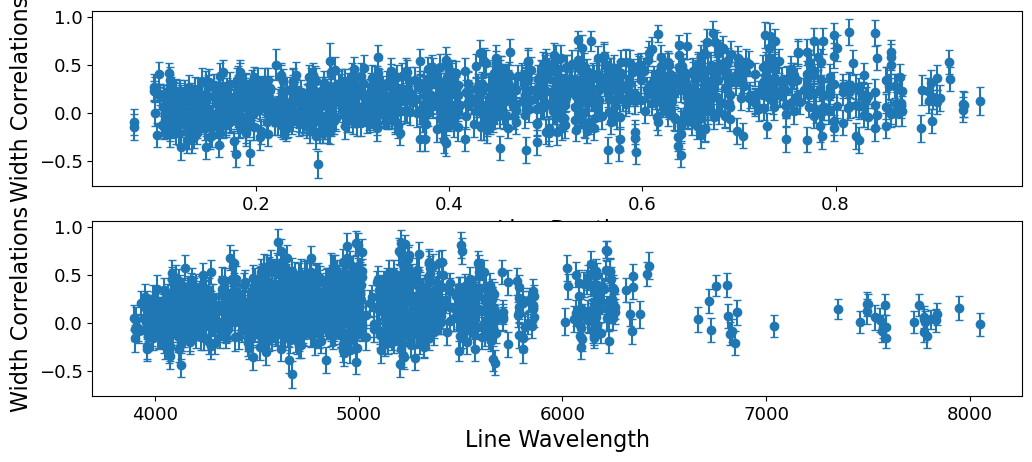

In [140]:
plt.subplot(2, 1, 1)
plt.errorbar(good_line_depths, corrs_w_uncs_mc['wids'].flatten(), yerr=corrs_w_uncs_mc['wids_unc'].flatten(), fmt='o')
plt.xlabel('Line Depth')
plt.ylabel('Width Correlations')
plt.subplot(2, 1, 2)
plt.errorbar(good_line_wls, corrs_w_uncs_mc['wids'].flatten(), yerr=corrs_w_uncs_mc['wids_unc'].flatten(), fmt='o')
plt.xlabel('Line Wavelength')
plt.ylabel('Width Correlations')
#plt.ylim(-20,0)

Text(0, 0.5, 'Center Correlations')

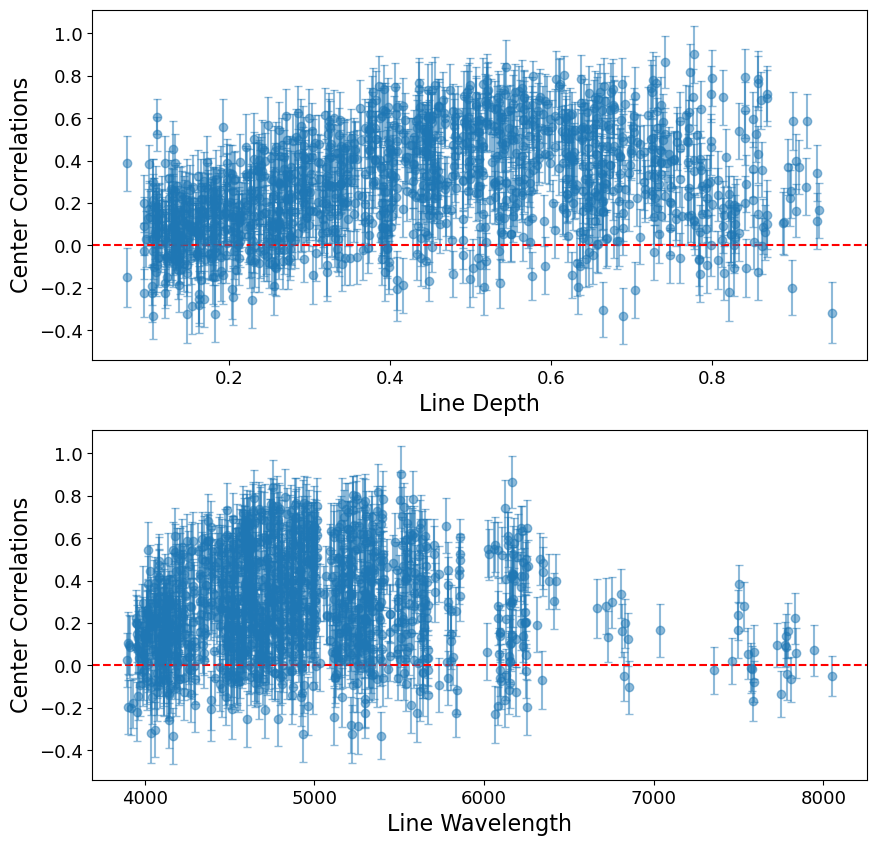

In [141]:
plt.figure(figsize=(10, 10))
plt.subplot(2, 1, 1)
plt.errorbar(good_line_depths, corrs_w_uncs_mc['cens'].flatten(), yerr=corrs_w_uncs_mc['cens_unc'].flatten(), fmt='o',alpha=0.5)
#plot y=0
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Line Depth')
plt.ylabel('Center Correlations')
plt.subplot(2, 1, 2)
plt.errorbar(good_line_wls, corrs_w_uncs_mc['cens'].flatten(), yerr=corrs_w_uncs_mc['cens_unc'].flatten(), fmt='o',alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Line Wavelength')
plt.ylabel('Center Correlations')
#plt.ylim(-20,0)

Text(0, 0.5, 'Amplitude Correlations')

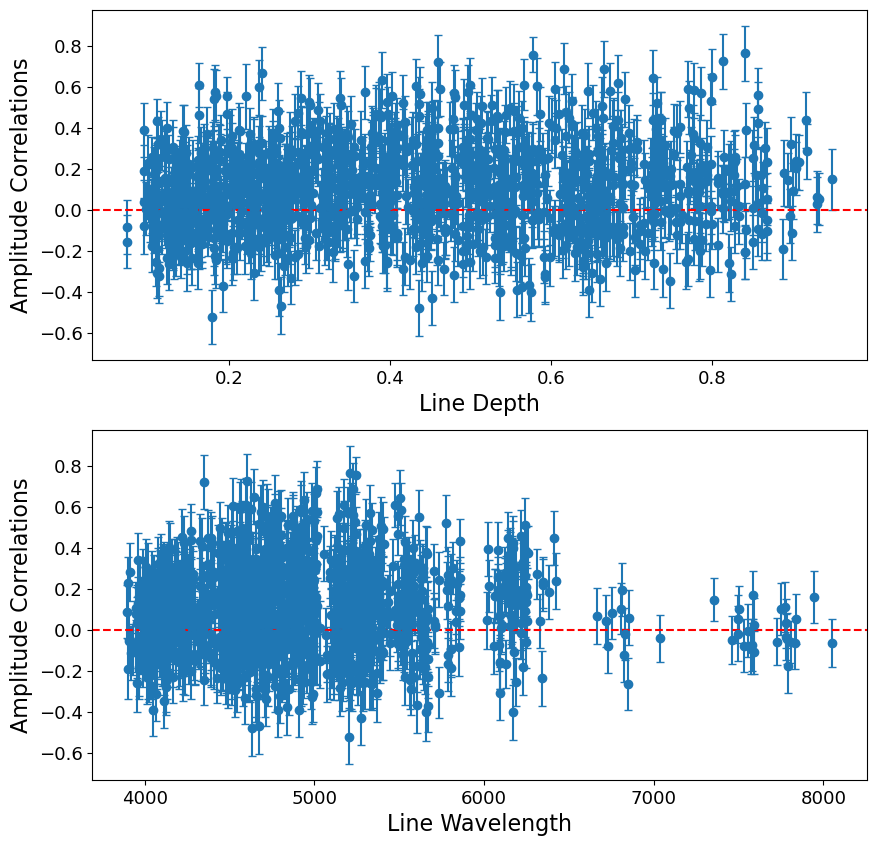

In [142]:
plt.figure(figsize=(10, 10))
plt.subplot(2, 1, 1)
plt.errorbar(good_line_depths, corrs_w_uncs_mc['amps'].flatten(), yerr=corrs_w_uncs_mc['amps_unc'].flatten(), fmt='o')
#plot y=0
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Line Depth')
plt.ylabel('Amplitude Correlations')
plt.subplot(2, 1, 2)
plt.errorbar(good_line_wls, corrs_w_uncs_mc['amps'].flatten(), yerr=corrs_w_uncs_mc['amps_unc'].flatten(), fmt='o')
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Line Wavelength')
plt.ylabel('Amplitude Correlations')
#plt.ylim(-20,0)

Text(0, 0.5, 'Correlation of cens')

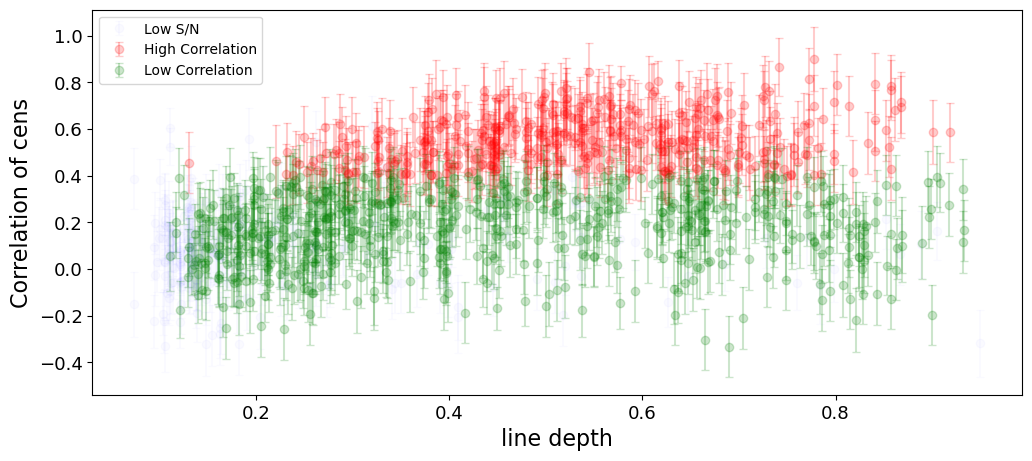

In [143]:
key='cens'
#plot low s2n
plt.errorbar(good_line_depths[low_s2n], corrs_w_uncs_mc[key].flatten()[low_s2n],
              yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[low_s2n],
              fmt='o',alpha=0.02,color='blue',label='Low S/N')
#plot high correlation
plt.errorbar(good_line_depths[high_corr], corrs_w_uncs_mc[key].flatten()[high_corr],
              yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[high_corr],
              fmt='o',alpha=0.2,color='red',label='High Correlation')
#plot low correlation
plt.errorbar(good_line_depths[low_corr], corrs_w_uncs_mc[key].flatten()[low_corr],
              yerr=corrs_w_uncs_mc[key+'_unc'].flatten()[low_corr],
              fmt='o',alpha=0.2,color='green',label='Low Correlation')
plt.legend()
#plt.hlines(0, -20, 0, colors='k', linestyles='dashed')
plt.xlabel('line depth')
plt.ylabel('Correlation of '+key)
#plt.xlim(-20,0)

In [144]:
good_line_depths[low_s2n]

array([0.88805409, 0.40128843, 0.57681417, 0.43916172, 0.64746973,
       0.26212739, 0.36623873, 0.5196846 , 0.94942526, 0.25757026,
       0.54464794, 0.17985838, 0.18596021, 0.26176968, 0.45528   ,
       0.20810333, 0.16097035, 0.79874339, 0.44483144, 0.68517576,
       0.18197116, 0.18731262, 0.78431216, 0.72819459, 0.90468577,
       0.76025027, 0.62695917, 0.36952364, 0.53103561, 0.59178897,
       0.53614314, 0.53614314, 0.86672766, 0.85196211, 0.39039792,
       0.17060048, 0.27661044, 0.32415222, 0.27595004, 0.26240504,
       0.26240504, 0.13853854, 0.13853854, 0.10607459, 0.10607459,
       0.3322132 , 0.46048054, 0.31528742, 0.52995518, 0.18989103,
       0.5348263 , 0.40945778, 0.40945778, 0.15274698, 0.35003476,
       0.34030634, 0.50805344, 0.13001562, 0.16610433, 0.21214003,
       0.12254975, 0.12254975, 0.22571892, 0.18438268, 0.12072433,
       0.14420408, 0.14420408, 0.39850603, 0.10984745, 0.10984745,
       0.22737605, 0.20405029, 0.25657049, 0.12134969, 0.12134

In [145]:
low_s2n

array([False,  True, False, ...,  True,  True, False], shape=(1292,))

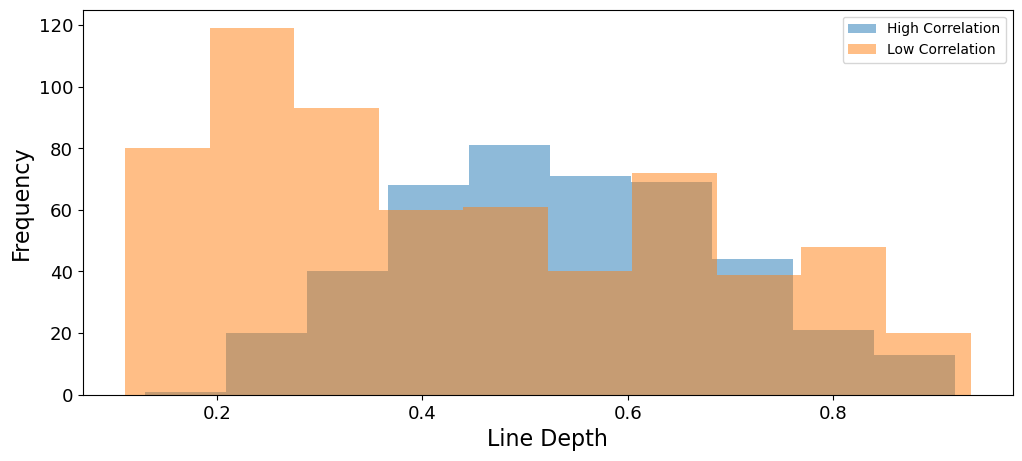

In [146]:
plt.hist(good_line_depths[high_corr],label='High Correlation',alpha=0.5)
plt.hist(good_line_depths[low_corr],label='Low Correlation',alpha=0.5)
plt.xlabel('Line Depth')
plt.ylabel('Frequency')
plt.legend()

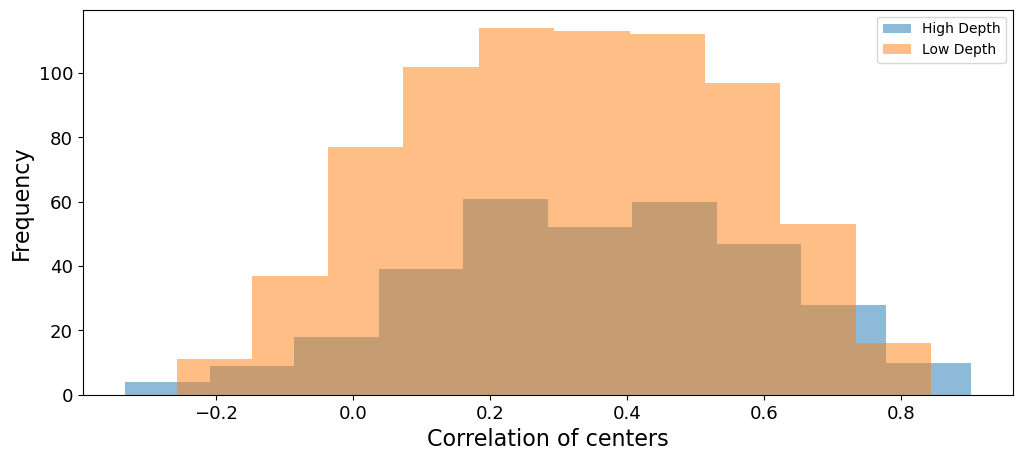

In [147]:
plt.hist(corrs_w_uncs_mc['cens'].flatten()[high_depth],label='High Depth',alpha=0.5)
plt.hist(corrs_w_uncs_mc['cens'].flatten()[low_depth],label='Low Depth',alpha=0.5)
plt.xlabel('Correlation of centers')
plt.ylabel('Frequency')
plt.legend()

In [148]:
mannwhitneyu(corrs_w_uncs_mc['cens'][high_depth],corrs_w_uncs_mc['cens'][low_depth])

MannwhitneyuResult(statistic=np.float64(132280.0), pvalue=np.float64(0.007937215338088503))

In [149]:
mannwhitneyu(good_line_depths[high_corr],good_line_depths[low_corr])

MannwhitneyuResult(statistic=np.float64(175582.5), pvalue=np.float64(1.6169785907128159e-16))

In [150]:
mannwhitneyu(corrs_w_uncs_mc['cens'].flatten()[depth_p2_p4], corrs_w_uncs_mc['cens'].flatten()[depth_p4_p6])

MannwhitneyuResult(statistic=np.float64(28395.0), pvalue=np.float64(7.697820035929472e-22))

In [151]:
mannwhitneyu(corrs_w_uncs_mc['cens'].flatten()[depth_p4_p6], corrs_w_uncs_mc['cens'].flatten()[high_depth])

MannwhitneyuResult(statistic=np.float64(60716.0), pvalue=np.float64(3.132577496672999e-05))

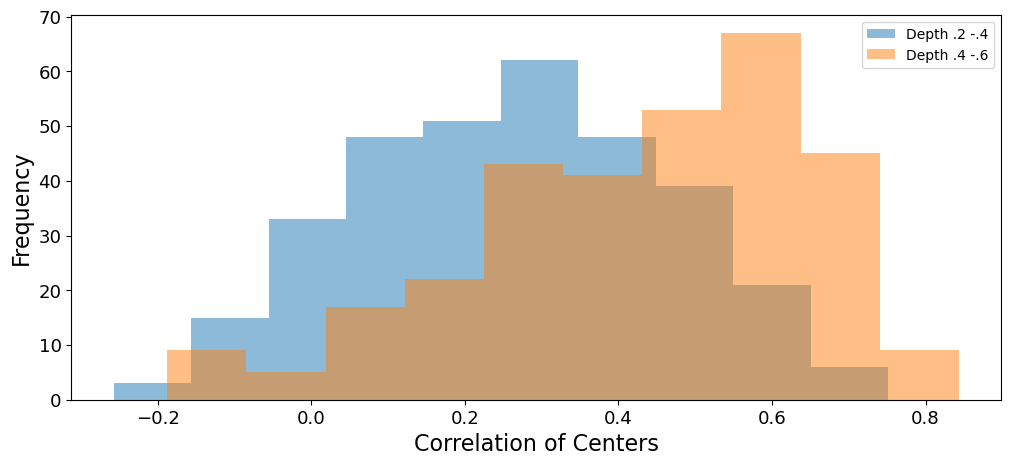

In [157]:
plt.hist(corrs_w_uncs_mc['cens'].flatten()[depth_p2_p4],label='Depth .2 -.4',alpha=0.5)
plt.hist(corrs_w_uncs_mc['cens'].flatten()[depth_p4_p6],label='Depth .4 -.6',alpha=0.5)
#plt.hist(corrs_w_uncs_mc['cens'].flatten()[high_depth],label='High Depth',alpha=0.5)
plt.xlabel('Correlation of Centers')
plt.ylabel('Frequency')
plt.legend()

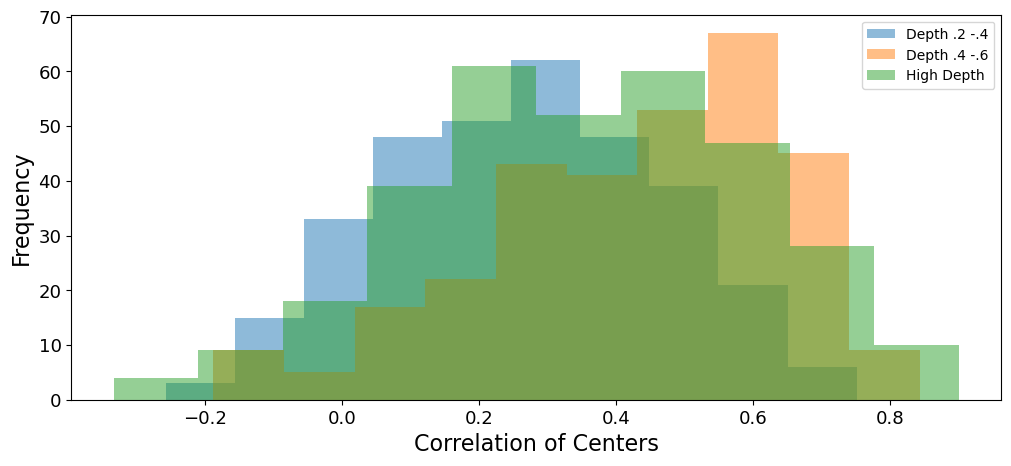

In [156]:
plt.hist(corrs_w_uncs_mc['cens'].flatten()[depth_p2_p4],label='Depth .2 -.4',alpha=0.5)
plt.hist(corrs_w_uncs_mc['cens'].flatten()[depth_p4_p6],label='Depth .4 -.6',alpha=0.5)
plt.hist(corrs_w_uncs_mc['cens'].flatten()[high_depth],label='High Depth',alpha=0.5)
plt.xlabel('Correlation of Centers')
plt.ylabel('Frequency')
plt.legend()

In [153]:
print(good_line_wls[high_variability])

[4837.5767698  5014.08560129 5272.50794837 5300.2432314  5860.39338281
 5860.39338281]
